
# 09b — dl tuning

## Purpose

This notebook implements and tunes the dissertation's primary deep-learning model:

> **A compact GRIN-inspired graph-enhanced bidirectional GRU for PM2.5 imputation**

The notebook begins with a short pilot profile and then supports the locked full tuning protocol.

### What this notebook does

- loads the data and training contract produced by Notebook 09a;
- reconstructs the Train and fixed Validation tensors independently;
- generates deterministic epoch-wise artificial Train masks;
- builds centred windows on demand rather than materialising them in memory;
- implements the graph-enhanced bidirectional GRU;
- trains with NaN-safe, window-balanced masked L1 loss at every artificially hidden centre-step target;
- uses family-balanced Validation MAE for early stopping and candidate selection;
- checkpoints each candidate and supports safe resume;
- saves tuning histories, learning curves, search diagnostics, scenario-level candidate diagnostics and the selected graph-model configuration.

### What this notebook does not do

- it does not evaluate Test data;
- it does not select models using Test results;
- it does not yet run the final zero-neighbour ablation;
- it does not produce the final Statistical–ML–DL comparison.

The final graph model and its no-neighbour control will be fitted and evaluated in Notebook 09c after the full Validation tuning is frozen.

## Required run order

1. Run Notebook 09a successfully.
2. Keep `RUN_PROFILE = "pilot"` and run this notebook from top to bottom.
3. Confirm that the pilot completes without failed assertions, non-finite losses or target-count mismatches.
4. Change only `RUN_PROFILE` from `"pilot"` to `"full"`.
5. Restart the kernel and run all cells again.
6. Do not modify the candidate table after inspecting Validation results.

The pilot is a computational and implementation check. It is **not** the final hyperparameter selection.

In [1]:
# ============================================================
# Step 1: Imports, deterministic settings and device metadata
# ============================================================

from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import platform
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any

# Must be set before CUDA linear-algebra operations are initialised.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, Dataset

SEED = 42
MODEL_INITIALISATION_SEED = 4242
TRAIN_MASK_BASE_SEED = 42000
TRAIN_ORDER_BASE_SEED = 52000
VALIDATION_SUBSET_SEED = 62000
PIPELINE_VERSION = "dl_tuning_v5_results_path_2026-07-24"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory GB:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    )

print("Platform:", platform.platform())

Python: 3.11.15
NumPy: 2.4.6
pandas: 3.0.5
PyTorch: 2.11.0+cu128
Device: cuda
CUDA available: True
PyTorch CUDA: 12.8
GPU: NVIDIA GeForce GTX 1660 Ti
GPU memory GB: 6.0
Platform: Windows-10-10.0.19045-SP0


In [2]:
# ============================================================
# Step 2: Resolve project paths and Notebook 0a artefacts
# ============================================================

def find_codes_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        Path.home() / "Desktop" / "DISSERTATION" / "Codes",
    ]

    for candidate in candidates:
        candidate = candidate.resolve()

        if (
            (candidate / "data").exists()
            and (candidate / "notebooks").exists()
        ):
            return candidate

        if candidate.name == "notebooks" and (candidate.parent / "data").exists():
            return candidate.parent

    raise FileNotFoundError(
        "Could not locate the dissertation Codes root. Open this notebook "
        "from Codes/notebooks or update find_codes_root()."
    )


CODES_ROOT = find_codes_root()

PROCESSED_DIR = CODES_ROOT / "data" / "processed"
MODELLING_DIR = CODES_ROOT / "data" / "modelling"
NOTEBOOKS_DIR = CODES_ROOT / "notebooks"

RESULTS_DIR = CODES_ROOT / "results"

DL_RESULTS_DIR = (
    RESULTS_DIR
    / "deep_learning"
)

AUDIT_OUTPUT_DIR = (
    DL_RESULTS_DIR
    / "08a_data_audit"
)

TUNING_OUTPUT_DIR = (
    DL_RESULTS_DIR
    / "08b_tuning"
)

DL_MODEL_DIR = (
    CODES_ROOT
    / "models"
    / "deep_learning"
)

CONTRACT_PATH = (
    AUDIT_OUTPUT_DIR
    / "dl_data_and_training_contract_manifest.json"
)

NORMALISATION_PATH = (
    AUDIT_OUTPUT_DIR
    / "dl_train_normalisation_stats.json"
)

ADJACENCY_PATH = (
    AUDIT_OUTPUT_DIR
    / "dl_top3_idw_neighbour_adjacency.npy"
)


for required_path in [
    CONTRACT_PATH,
    NORMALISATION_PATH,
    ADJACENCY_PATH,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required Notebook 08a artefact not found: {required_path}"
        )

print("Codes root:", CODES_ROOT)
print("Results directory:", RESULTS_DIR)
print("DL results directory:", DL_RESULTS_DIR)
print("08a audit directory:", AUDIT_OUTPUT_DIR)
print("08b tuning directory:", TUNING_OUTPUT_DIR)
print("Notebook 08a contract:", CONTRACT_PATH)
print("DL model directory:", DL_MODEL_DIR)

Codes root: C:\Users\Msi\Desktop\DISSERTATION\Codes
Results directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results
DL results directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning
08a audit directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit
08b tuning directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08b_tuning
Notebook 08a contract: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_data_and_training_contract_manifest.json
DL model directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\deep_learning


In [3]:
# ============================================================
# Step 3: Choose pilot or full profile
# ============================================================

# Run the pilot first. After it passes, change only this line to "full".
RUN_PROFILE = "full"

if RUN_PROFILE not in {"pilot", "full"}:
    raise ValueError("RUN_PROFILE must be 'pilot' or 'full'.")

PROFILE_SETTINGS = {
    "pilot": {
        "candidate_ids": [1, 10],
        "maximum_epochs": 3,
        "patience": 2,
        "train_samples_per_epoch": 256,
        "maximum_validation_windows_per_scenario": 256,
        "resume_completed_candidates": False,
    },
    "full": {
        "candidate_ids": list(range(1, 13)),
        "maximum_epochs": 100,
        "patience": 10,
        "train_samples_per_epoch": 2048,
        "maximum_validation_windows_per_scenario": None,
        "resume_completed_candidates": True,
    },
}

PROFILE = PROFILE_SETTINGS[RUN_PROFILE]

BATCH_SIZE = 32
VALIDATION_BATCH_SIZE = 64
DATALOADER_NUM_WORKERS = 0
EARLY_STOPPING_MIN_DELTA = 1e-4
GRADIENT_CLIP_NORM = 1.0
BLOCK_BACKGROUND_COVERAGE = 0.10

PROFILE_OUTPUT_DIR = (
    TUNING_OUTPUT_DIR
    / PIPELINE_VERSION
    / RUN_PROFILE
)

PROFILE_MODEL_DIR = (
    DL_MODEL_DIR
    / "tuning"
    / PIPELINE_VERSION
    / RUN_PROFILE
)

PROFILE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROFILE_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Run profile:", RUN_PROFILE)
print(json.dumps(PROFILE, indent=2))
print("Profile output directory:", PROFILE_OUTPUT_DIR)
print("Profile model directory:", PROFILE_MODEL_DIR)

if RUN_PROFILE == "pilot":
    print(
        "\nPILOT MODE: outputs are implementation checks and must not "
        "be reported as final tuning results."
    )

Run profile: full
{
  "candidate_ids": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12
  ],
  "maximum_epochs": 100,
  "patience": 10,
  "train_samples_per_epoch": 2048,
  "maximum_validation_windows_per_scenario": null,
  "resume_completed_candidates": true
}
Profile output directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08b_tuning\dl_tuning_v5_results_path_2026-07-24\full
Profile model directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\deep_learning\tuning\dl_tuning_v5_results_path_2026-07-24\full


In [4]:
# ============================================================
# Step 4: Locked compact candidate table
# ============================================================

# The 12 configurations balance every value in the predefined search space:
# - context: 6 × 96h and 6 × 168h
# - hidden units: 6 × 32 and 6 × 64
# - recurrent layers: 6 × 1 and 6 × 2
# - dropout: each value appears four times
# - learning rate: each value appears four times
#
# This is a compact, non-exhaustive search. The table must not be modified
# after Validation results have been inspected.

CANDIDATES = [
    {
        "CandidateID": 1,
        "context_hours": 96,
        "hidden_units": 32,
        "recurrent_layers": 1,
        "dropout": 0.0,
        "learning_rate": 1e-3,
    },
    {
        "CandidateID": 2,
        "context_hours": 96,
        "hidden_units": 32,
        "recurrent_layers": 1,
        "dropout": 0.2,
        "learning_rate": 5e-4,
    },
    {
        "CandidateID": 3,
        "context_hours": 96,
        "hidden_units": 32,
        "recurrent_layers": 2,
        "dropout": 0.4,
        "learning_rate": 2e-4,
    },
    {
        "CandidateID": 4,
        "context_hours": 96,
        "hidden_units": 64,
        "recurrent_layers": 1,
        "dropout": 0.4,
        "learning_rate": 5e-4,
    },
    {
        "CandidateID": 5,
        "context_hours": 96,
        "hidden_units": 64,
        "recurrent_layers": 2,
        "dropout": 0.0,
        "learning_rate": 2e-4,
    },
    {
        "CandidateID": 6,
        "context_hours": 96,
        "hidden_units": 64,
        "recurrent_layers": 2,
        "dropout": 0.2,
        "learning_rate": 1e-3,
    },
    {
        "CandidateID": 7,
        "context_hours": 168,
        "hidden_units": 32,
        "recurrent_layers": 1,
        "dropout": 0.4,
        "learning_rate": 2e-4,
    },
    {
        "CandidateID": 8,
        "context_hours": 168,
        "hidden_units": 32,
        "recurrent_layers": 2,
        "dropout": 0.0,
        "learning_rate": 5e-4,
    },
    {
        "CandidateID": 9,
        "context_hours": 168,
        "hidden_units": 32,
        "recurrent_layers": 2,
        "dropout": 0.2,
        "learning_rate": 1e-3,
    },
    {
        "CandidateID": 10,
        "context_hours": 168,
        "hidden_units": 64,
        "recurrent_layers": 1,
        "dropout": 0.0,
        "learning_rate": 1e-3,
    },
    {
        "CandidateID": 11,
        "context_hours": 168,
        "hidden_units": 64,
        "recurrent_layers": 1,
        "dropout": 0.2,
        "learning_rate": 2e-4,
    },
    {
        "CandidateID": 12,
        "context_hours": 168,
        "hidden_units": 64,
        "recurrent_layers": 2,
        "dropout": 0.4,
        "learning_rate": 5e-4,
    },
]

candidate_df = pd.DataFrame(CANDIDATES)

assert len(candidate_df) == 12
assert set(candidate_df["CandidateID"]) == set(range(1, 13))
assert candidate_df["context_hours"].value_counts().to_dict() == {
    96: 6,
    168: 6,
}
assert candidate_df["hidden_units"].value_counts().to_dict() == {
    32: 6,
    64: 6,
}
assert candidate_df["recurrent_layers"].value_counts().to_dict() == {
    1: 6,
    2: 6,
}
assert set(candidate_df["dropout"].value_counts()) == {4}
assert set(candidate_df["learning_rate"].value_counts()) == {4}

selected_candidate_df = candidate_df.loc[
    candidate_df["CandidateID"].isin(PROFILE["candidate_ids"])
].copy()

selected_candidate_df.to_csv(
    PROFILE_OUTPUT_DIR / "dl_candidate_table.csv",
    index=False,
)

display(selected_candidate_df)

,CandidateID,context_hours,hidden_units,recurrent_layers,dropout,learning_rate
0,1,96,32,1,0.0,0.0010
1,2,96,32,1,0.2,0.0005
2,3,96,32,2,0.4,0.0002
3,4,96,64,1,0.4,0.0005
4,5,96,64,2,0.0,0.0002
5,6,96,64,2,0.2,0.0010
6,7,168,32,1,0.4,0.0002
7,8,168,32,2,0.0,0.0005
8,9,168,32,2,0.2,0.0010
9,10,168,64,1,0.0,0.0010


In [5]:
# ============================================================
# Step 5: Load and validate the Notebook 09a contract
# ============================================================

contract = json.loads(CONTRACT_PATH.read_text(encoding="utf-8"))
normalisation_stats = json.loads(
    NORMALISATION_PATH.read_text(encoding="utf-8")
)
A_NEIGHBOUR = np.load(ADJACENCY_PATH).astype(np.float32)

assert contract["Status"] == "data_and_training_contract_complete"
assert contract["NumberOfStations"] == 5
assert contract["ContextHoursCandidates"] == [96, 168]
assert contract["GraphDefinition"]["MessagePassingLayers"] == 1
assert contract["GraphDefinition"]["NeighbourProjectionBias"] is False
assert contract["GraphDefinition"]["BatchNorm"] is False
assert contract["GraphDefinition"]["PostFusionLayerNorm"] is False
assert contract["TrainingContract"]["Loss"] == "masked_l1"
assert (
    contract["TrainingContract"]["ValidationSelectionMetric"]
    == "FamilyBalancedValidationMAE"
)
assert contract["TrainingContract"]["BatchSize"] == BATCH_SIZE
assert contract["TuningContract"]["CandidateBudget"] == 12

station_order = [str(value) for value in contract["StationOrder"]]
feature_names_contract = list(contract["FeatureNames"])

assert A_NEIGHBOUR.shape == (5, 5)
np.testing.assert_allclose(
    A_NEIGHBOUR.sum(axis=1),
    np.ones(5),
    atol=2e-3,
)
np.testing.assert_allclose(
    np.diag(A_NEIGHBOUR),
    np.zeros(5),
    atol=0.0,
)

PM25_MEAN = float(normalisation_stats["PM25"]["mean"])
PM25_STD = float(normalisation_stats["PM25"]["std"])
TEMPERATURE_MEAN = float(normalisation_stats["Temperature"]["mean"])
TEMPERATURE_STD = float(normalisation_stats["Temperature"]["std"])

assert PM25_STD > 0
assert TEMPERATURE_STD > 0

contract_fingerprint = hashlib.sha256(
    CONTRACT_PATH.read_bytes()
).hexdigest()

print("Contract fingerprint:", contract_fingerprint)
print("Station order:", station_order)
print("Input features:", len(feature_names_contract))
print("PM2.5 Train mean/std:", PM25_MEAN, PM25_STD)

Contract fingerprint: f07c6a2e2e3168141892f956fd013cec930a387d9f96aa32f43f20066b75eb50
Station order: ['London Bexley', 'London Harlington', 'London Honor Oak Park', 'London Marylebone Road', 'London N. Kensington']
Input features: 18
PM2.5 Train mean/std: 8.762305030114813 7.403844648403524


In [6]:
# ============================================================
# Step 6: File discovery and split-tensor construction
# ============================================================

SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent",
]

RANDOM_SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
]

BLOCK_SCENARIOS = [
    "block24_10percent",
    "block72_10percent",
]

EXPECTED_VALIDATION_TARGETS = {
    "random10_point": 4332,
    "random30_point": 12997,
    "random50_point": 21660,
    "block24_10percent": 4392,
    "block72_10percent": 4608,
}

REQUIRED_COLUMNS = [
    "Station",
    "Datetime",
    "Split",
    "Temperature",
    "PM25_original",
    "PM25_model_input",
    "is_real_missing",
    "is_artificial_masked",
]


def first_existing(paths: list[Path]) -> Path:
    for path in paths:
        if path.exists():
            return path

    raise FileNotFoundError(
        "None of the expected files exists:\n"
        + "\n".join(map(str, paths))
    )


base_path = first_existing([
    MODELLING_DIR / "base_modelling_dataset_before_masking.csv",
    PROCESSED_DIR / "base_modelling_dataset_before_masking.csv",
])

scenario_paths = {
    scenario: first_existing([
        MODELLING_DIR / f"modelling_dataset_{scenario}_masked.csv",
        PROCESSED_DIR / f"modelling_dataset_{scenario}_masked.csv",
    ])
    for scenario in SCENARIOS
}


def standardise_with_mask(
    values: np.ndarray,
    mean: float,
    std: float,
) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(values, dtype=np.float32)
    observed = np.isfinite(values).astype(np.float32)

    standardised = (values - mean) / std
    standardised[~np.isfinite(standardised)] = 0.0

    return standardised.astype(np.float32), observed


def directional_gap_hours(
    observed_mask: np.ndarray,
    direction: str,
    max_hours: int = 168,
) -> np.ndarray:
    observed_mask = np.asarray(observed_mask, dtype=bool)
    n = len(observed_mask)
    gaps = np.full(n, max_hours, dtype=np.float32)

    if direction == "previous":
        last_observed = None

        for index in range(n):
            if observed_mask[index]:
                gaps[index] = 0.0
                last_observed = index
            elif last_observed is not None:
                gaps[index] = min(index - last_observed, max_hours)

    elif direction == "next":
        next_observed = None

        for index in range(n - 1, -1, -1):
            if observed_mask[index]:
                gaps[index] = 0.0
                next_observed = index
            elif next_observed is not None:
                gaps[index] = min(next_observed - index, max_hours)

    else:
        raise ValueError("direction must be 'previous' or 'next'.")

    return (
        np.log1p(gaps) / np.log1p(float(max_hours))
    ).astype(np.float32)


def build_split_tensor(
    split_df: pd.DataFrame,
    expected_split: str,
) -> dict[str, Any]:
    split_df = split_df.copy()

    assert set(split_df["Split"].unique()) == {expected_split}

    split_df["Station"] = pd.Categorical(
        split_df["Station"],
        categories=station_order,
        ordered=True,
    )

    split_df = split_df.sort_values(
        ["Datetime", "Station"]
    ).reset_index(drop=True)

    timestamps = np.sort(split_df["Datetime"].unique())
    expected_rows = len(timestamps) * len(station_order)

    assert len(split_df) == expected_rows
    assert not split_df.duplicated(["Station", "Datetime"]).any()

    station_counts = split_df.groupby(
        "Datetime",
        observed=False,
    )["Station"].nunique()

    assert (station_counts == len(station_order)).all()

    def pivot(column: str) -> np.ndarray:
        return (
            split_df
            .pivot(index="Datetime", columns="Station", values=column)
            .reindex(index=timestamps, columns=station_order)
            .to_numpy()
        )

    pm25_input = pivot("PM25_model_input").astype(np.float32)
    pm25_truth = pivot("PM25_original").astype(np.float32)
    temperature = pivot("Temperature").astype(np.float32)
    artificial_target = pivot("is_artificial_masked").astype(bool)
    real_missing = pivot("is_real_missing").astype(bool)

    pm25_z, pm25_observed = standardise_with_mask(
        pm25_input,
        PM25_MEAN,
        PM25_STD,
    )
    temperature_z, temperature_observed = standardise_with_mask(
        temperature,
        TEMPERATURE_MEAN,
        TEMPERATURE_STD,
    )

    datetime_index = pd.DatetimeIndex(timestamps)

    hour_angle = (
        2.0 * np.pi * datetime_index.hour.to_numpy() / 24.0
    )
    dow_angle = (
        2.0 * np.pi * datetime_index.dayofweek.to_numpy() / 7.0
    )
    month_angle = (
        2.0
        * np.pi
        * (datetime_index.month.to_numpy() - 1)
        / 12.0
    )

    calendar = np.column_stack([
        np.sin(hour_angle),
        np.cos(hour_angle),
        np.sin(dow_angle),
        np.cos(dow_angle),
        np.sin(month_angle),
        np.cos(month_angle),
    ]).astype(np.float32)

    calendar = np.repeat(
        calendar[:, None, :],
        repeats=len(station_order),
        axis=1,
    )

    delta_previous = np.zeros_like(pm25_z, dtype=np.float32)
    delta_next = np.zeros_like(pm25_z, dtype=np.float32)

    for station_index in range(len(station_order)):
        station_observed = pm25_observed[:, station_index].astype(bool)

        delta_previous[:, station_index] = directional_gap_hours(
            station_observed,
            direction="previous",
        )
        delta_next[:, station_index] = directional_gap_hours(
            station_observed,
            direction="next",
        )

    station_one_hot = np.eye(
        len(station_order),
        dtype=np.float32,
    )

    station_one_hot = np.repeat(
        station_one_hot[None, :, :],
        repeats=len(timestamps),
        axis=0,
    )

    valid_time_mask = np.ones(
        (len(timestamps), len(station_order), 1),
        dtype=np.float32,
    )

    features = np.concatenate([
        pm25_z[..., None],
        pm25_observed[..., None],
        temperature_z[..., None],
        temperature_observed[..., None],
        calendar,
        delta_previous[..., None],
        delta_next[..., None],
        station_one_hot,
        valid_time_mask,
    ], axis=-1).astype(np.float32)

    feature_names = [
        "PM25_value_z",
        "PM25_observed_mask",
        "Temperature_z",
        "Temperature_observed_mask",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "Month_sin",
        "Month_cos",
        "HoursSincePreviousObserved_scaled",
        "HoursUntilNextObserved_scaled",
        *[f"Station_{station}" for station in station_order],
        "ValidTimeStep",
    ]

    assert feature_names == feature_names_contract
    assert features.shape == (
        len(timestamps),
        len(station_order),
        len(feature_names),
    )

    return {
        "features": features,
        "feature_names": feature_names,
        "truth": pm25_truth,
        "artificial_target_mask": artificial_target,
        "real_missing_mask": real_missing,
        "timestamps": datetime_index,
        "station_order": station_order,
    }

In [7]:
# ============================================================
# Step 7: Load Train once and fixed Validation scenarios
# ============================================================

base_df = pd.read_csv(
    base_path,
    usecols=REQUIRED_COLUMNS,
    parse_dates=["Datetime"],
)

train_df = base_df.loc[
    base_df["Split"].eq("Train")
].copy()

del base_df

assert set(train_df["Split"].unique()) == {"Train"}
assert int(train_df["is_artificial_masked"].sum()) == 0

train_bundle = build_split_tensor(
    train_df,
    expected_split="Train",
)

del train_df

validation_bundles: dict[str, dict[str, Any]] = {}

validation_target_audit = []

for scenario, scenario_path in scenario_paths.items():
    scenario_df = pd.read_csv(
        scenario_path,
        usecols=REQUIRED_COLUMNS,
        parse_dates=["Datetime"],
    )

    validation_df = scenario_df.loc[
        scenario_df["Split"].eq("Validation")
    ].copy()

    del scenario_df

    assert set(validation_df["Split"].unique()) == {"Validation"}

    bundle = build_split_tensor(
        validation_df,
        expected_split="Validation",
    )

    del validation_df

    target_count = int(bundle["artificial_target_mask"].sum())

    assert target_count == EXPECTED_VALIDATION_TARGETS[scenario], (
        f"{scenario}: expected "
        f"{EXPECTED_VALIDATION_TARGETS[scenario]} Validation targets, "
        f"found {target_count}"
    )
    assert np.isfinite(
        bundle["truth"][bundle["artificial_target_mask"]]
    ).all()

    validation_bundles[scenario] = bundle

    validation_target_audit.append({
        "Scenario": scenario,
        "ValidationTargetRows": target_count,
        "UniqueTargetTimestamps": int(
            bundle["artificial_target_mask"].any(axis=1).sum()
        ),
    })

validation_target_audit_df = pd.DataFrame(validation_target_audit)
display(validation_target_audit_df)

validation_target_audit_df.to_csv(
    PROFILE_OUTPUT_DIR / "validation_target_audit.csv",
    index=False,
)

print("Train tensor:", train_bundle["features"].shape)
print("Fixed Validation scenario tensors loaded:", len(validation_bundles))
print("No Test metrics or Test tensors were created.")

,Scenario,ValidationTargetRows,UniqueTargetTimestamps
0,random10_point,4332,3594
1,random30_point,12997,7284
2,random50_point,21660,8489
3,block24_10percent,4392,3662
4,block72_10percent,4608,3547


Train tensor: (26280, 5, 18)
Fixed Validation scenario tensors loaded: 5
No Test metrics or Test tensors were created.


In [8]:
# ============================================================
# Step 8: Feature indices and graph-message channels
# ============================================================

FEATURE_NAMES = train_bundle["feature_names"]

PM25_VALUE_INDEX = FEATURE_NAMES.index("PM25_value_z")
PM25_MASK_INDEX = FEATURE_NAMES.index("PM25_observed_mask")
PREVIOUS_GAP_INDEX = FEATURE_NAMES.index(
    "HoursSincePreviousObserved_scaled"
)
NEXT_GAP_INDEX = FEATURE_NAMES.index(
    "HoursUntilNextObserved_scaled"
)

# Only node-varying sensor and missingness channels are passed through
# the neighbour branch. Calendar and station-identity channels remain
# in the self pathway and are not duplicated by graph aggregation.
NEIGHBOUR_FEATURE_NAMES = [
    "PM25_value_z",
    "PM25_observed_mask",
    "Temperature_z",
    "Temperature_observed_mask",
    "HoursSincePreviousObserved_scaled",
    "HoursUntilNextObserved_scaled",
]

NEIGHBOUR_FEATURE_INDICES = [
    FEATURE_NAMES.index(name)
    for name in NEIGHBOUR_FEATURE_NAMES
]

assert len(NEIGHBOUR_FEATURE_INDICES) == 6
assert len(set(NEIGHBOUR_FEATURE_INDICES)) == 6

print("Total input features:", len(FEATURE_NAMES))
print("Neighbour-message features:", NEIGHBOUR_FEATURE_NAMES)

Total input features: 18
Neighbour-message features: ['PM25_value_z', 'PM25_observed_mask', 'Temperature_z', 'Temperature_observed_mask', 'HoursSincePreviousObserved_scaled', 'HoursUntilNextObserved_scaled']


In [9]:
# ============================================================
# Step 9: Candidate-independent epoch-wise Train mask plans
# ============================================================

@dataclass(frozen=True)
class TrainMaskRecord:
    family: str
    scenario: str
    center_index: int
    target_node: int
    random_rate: float | None
    block_duration: int | None
    block_start: int | None
    mask_seed: int


class EpochMaskPlanFactory:
    """
    Creates the same target centres, scenario sequence and mask seeds for
    every candidate at a given epoch.

    A maximum 168-hour centred window defines the shared augmentation
    canvas. Candidates using 96 hours receive the central crop of the
    same augmentation pattern.
    """

    def __init__(
        self,
        bundle: dict[str, Any],
        maximum_context_hours: int = 168,
        base_seed: int = TRAIN_MASK_BASE_SEED,
    ) -> None:
        self.truth = bundle["truth"]
        self.features = bundle["features"]
        self.feature_names = bundle["feature_names"]
        self.base_seed = int(base_seed)

        self.maximum_context_hours = int(maximum_context_hours)
        self.maximum_radius = self.maximum_context_hours // 2
        self.maximum_window_length = self.maximum_context_hours + 1

        self.time_steps = self.features.shape[0]
        self.number_of_nodes = self.features.shape[1]

        observed_truth = np.isfinite(self.truth)

        coordinates = np.argwhere(observed_truth)

        valid_coordinate_mask = (
            (coordinates[:, 0] >= self.maximum_radius)
            & (
                coordinates[:, 0]
                < self.time_steps - self.maximum_radius
            )
        )

        self.random_target_coordinates = coordinates[
            valid_coordinate_mask
        ]

        assert len(self.random_target_coordinates) > 0

        self.valid_block_options: dict[int, list[tuple[int, int, int, int]]] = {}

        for duration in [24, 72]:
            options: list[tuple[int, int, int, int]] = []

            for node_index in range(self.number_of_nodes):
                observed = observed_truth[:, node_index].astype(np.int16)

                rolling_sum = np.convolve(
                    observed,
                    np.ones(duration, dtype=np.int16),
                    mode="valid",
                )

                valid_starts = np.flatnonzero(
                    rolling_sum == duration
                )

                for block_start in valid_starts:
                    minimum_position = max(
                        0,
                        self.maximum_radius - int(block_start),
                    )
                    maximum_position = min(
                        duration - 1,
                        (
                            self.time_steps
                            - self.maximum_radius
                            - 1
                            - int(block_start)
                        ),
                    )

                    if minimum_position <= maximum_position:
                        options.append(
                            (
                                int(block_start),
                                int(node_index),
                                int(minimum_position),
                                int(maximum_position),
                            )
                        )

            assert len(options) > 0
            self.valid_block_options[duration] = options

    @staticmethod
    def _balanced_values(
        values: list[Any],
        count: int,
        rng: np.random.Generator,
    ) -> list[Any]:
        repeated = np.resize(
            np.asarray(values, dtype=object),
            count,
        ).tolist()

        rng.shuffle(repeated)
        return repeated

    def make_plan(
        self,
        epoch_number: int,
        number_of_samples: int,
    ) -> list[TrainMaskRecord]:
        if number_of_samples < 2:
            raise ValueError("number_of_samples must be at least 2.")

        rng = np.random.default_rng(
            self.base_seed + int(epoch_number)
        )

        number_random = number_of_samples // 2
        number_block = number_of_samples - number_random

        family_labels = (
            ["random"] * number_random
            + ["block"] * number_block
        )
        rng.shuffle(family_labels)

        random_scenarios = self._balanced_values(
            ["random10_point", "random30_point", "random50_point"],
            number_random,
            rng,
        )

        block_scenarios = self._balanced_values(
            ["block24_10percent", "block72_10percent"],
            number_block,
            rng,
        )

        random_cursor = 0
        block_cursor = 0
        plan: list[TrainMaskRecord] = []

        rate_lookup = {
            "random10_point": 0.10,
            "random30_point": 0.30,
            "random50_point": 0.50,
        }

        duration_lookup = {
            "block24_10percent": 24,
            "block72_10percent": 72,
        }

        for sample_index, family in enumerate(family_labels):
            mask_seed = (
                self.base_seed
                + int(epoch_number) * 1_000_003
                + sample_index
            )

            if family == "random":
                scenario = str(random_scenarios[random_cursor])
                random_cursor += 1

                coordinate = self.random_target_coordinates[
                    rng.integers(len(self.random_target_coordinates))
                ]

                plan.append(
                    TrainMaskRecord(
                        family="random",
                        scenario=scenario,
                        center_index=int(coordinate[0]),
                        target_node=int(coordinate[1]),
                        random_rate=float(rate_lookup[scenario]),
                        block_duration=None,
                        block_start=None,
                        mask_seed=int(mask_seed),
                    )
                )

            else:
                scenario = str(block_scenarios[block_cursor])
                block_cursor += 1

                duration = int(duration_lookup[scenario])
                options = self.valid_block_options[duration]

                (
                    block_start,
                    target_node,
                    minimum_position,
                    maximum_position,
                ) = options[rng.integers(len(options))]

                position_inside_block = int(
                    rng.integers(
                        minimum_position,
                        maximum_position + 1,
                    )
                )

                center_index = (
                    block_start + position_inside_block
                )

                plan.append(
                    TrainMaskRecord(
                        family="block",
                        scenario=scenario,
                        center_index=int(center_index),
                        target_node=int(target_node),
                        random_rate=None,
                        block_duration=duration,
                        block_start=int(block_start),
                        mask_seed=int(mask_seed),
                    )
                )

        assert len(plan) == number_of_samples
        assert sum(record.family == "random" for record in plan) == number_random
        assert sum(record.family == "block" for record in plan) == number_block

        return plan


mask_plan_factory = EpochMaskPlanFactory(
    train_bundle,
    maximum_context_hours=168,
)

pilot_plan = mask_plan_factory.make_plan(
    epoch_number=0,
    number_of_samples=PROFILE["train_samples_per_epoch"],
)

plan_audit_df = pd.DataFrame([
    {
        "Family": record.family,
        "Scenario": record.scenario,
    }
    for record in pilot_plan
])

display(
    plan_audit_df
    .value_counts(["Family", "Scenario"])
    .rename("Samples")
    .reset_index()
)

print("Epoch-wise mask-plan factory audit passed.")

,Family,Scenario,Samples
0,block,block24_10percent,512
1,block,block72_10percent,512
2,random,random10_point,342
3,random,random30_point,341
4,random,random50_point,341


Epoch-wise mask-plan factory audit passed.


In [10]:
# ============================================================
# Step 10: On-demand Train and Validation window datasets
# ============================================================

class DynamicMaskedTrainWindowDataset(Dataset):
    def __init__(
        self,
        bundle: dict[str, Any],
        plan_factory: EpochMaskPlanFactory,
        context_hours: int,
        number_of_samples: int,
    ) -> None:
        self.features = bundle["features"]
        self.truth = bundle["truth"]
        self.feature_names = bundle["feature_names"]

        self.plan_factory = plan_factory
        self.context_hours = int(context_hours)
        self.radius = self.context_hours // 2
        self.window_length = self.context_hours + 1
        self.number_of_samples = int(number_of_samples)

        self.maximum_radius = plan_factory.maximum_radius
        self.maximum_window_length = (
            plan_factory.maximum_window_length
        )

        self.time_steps = self.features.shape[0]
        self.number_of_nodes = self.features.shape[1]

        self.base_observed_mask = (
            self.features[..., PM25_MASK_INDEX] > 0.5
        )

        self.previous_observed_index = np.full(
            (self.time_steps, self.number_of_nodes),
            -1,
            dtype=np.int32,
        )
        self.next_observed_index = np.full(
            (self.time_steps, self.number_of_nodes),
            -1,
            dtype=np.int32,
        )

        for node_index in range(self.number_of_nodes):
            last_observed = -1

            for time_index in range(self.time_steps):
                if self.base_observed_mask[time_index, node_index]:
                    last_observed = time_index

                self.previous_observed_index[
                    time_index,
                    node_index,
                ] = last_observed

            next_observed = -1

            for time_index in range(
                self.time_steps - 1,
                -1,
                -1,
            ):
                if self.base_observed_mask[time_index, node_index]:
                    next_observed = time_index

                self.next_observed_index[
                    time_index,
                    node_index,
                ] = next_observed

        self.plan: list[TrainMaskRecord] = []
        self.current_epoch = -1
        self.set_epoch(0)

    def set_epoch(self, epoch_number: int) -> None:
        self.current_epoch = int(epoch_number)
        self.plan = self.plan_factory.make_plan(
            epoch_number=self.current_epoch,
            number_of_samples=self.number_of_samples,
        )

    def __len__(self) -> int:
        return self.number_of_samples

    def _recompute_gap_features_on_maximum_window(
        self,
        augmented_observed_mask: np.ndarray,
        global_start: int,
    ) -> tuple[np.ndarray, np.ndarray]:
        length, number_of_nodes = augmented_observed_mask.shape

        previous_gap = np.zeros(
            (length, number_of_nodes),
            dtype=np.float32,
        )
        next_gap = np.zeros(
            (length, number_of_nodes),
            dtype=np.float32,
        )

        maximum_gap = 168
        denominator = np.log1p(float(maximum_gap))

        global_end = global_start + length

        for node_index in range(number_of_nodes):
            if global_start > 0:
                previous_global = int(
                    self.previous_observed_index[
                        global_start - 1,
                        node_index,
                    ]
                )
            else:
                previous_global = -1

            last_observed_local = (
                previous_global - global_start
                if previous_global >= 0
                else None
            )

            raw_previous = np.full(
                length,
                maximum_gap,
                dtype=np.float32,
            )

            for local_index in range(length):
                if augmented_observed_mask[
                    local_index,
                    node_index,
                ]:
                    raw_previous[local_index] = 0.0
                    last_observed_local = local_index
                elif last_observed_local is not None:
                    raw_previous[local_index] = min(
                        local_index - last_observed_local,
                        maximum_gap,
                    )

            previous_gap[:, node_index] = (
                np.log1p(raw_previous) / denominator
            )

            if global_end < self.time_steps:
                next_global = int(
                    self.next_observed_index[
                        global_end,
                        node_index,
                    ]
                )
            else:
                next_global = -1

            next_observed_local = (
                next_global - global_start
                if next_global >= 0
                else None
            )

            raw_next = np.full(
                length,
                maximum_gap,
                dtype=np.float32,
            )

            for local_index in range(length - 1, -1, -1):
                if augmented_observed_mask[
                    local_index,
                    node_index,
                ]:
                    raw_next[local_index] = 0.0
                    next_observed_local = local_index
                elif next_observed_local is not None:
                    raw_next[local_index] = min(
                        next_observed_local - local_index,
                        maximum_gap,
                    )

            next_gap[:, node_index] = (
                np.log1p(raw_next) / denominator
            )

        return previous_gap, next_gap

    def __getitem__(
        self,
        sample_index: int,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        record = self.plan[sample_index]

        maximum_start = (
            record.center_index - self.maximum_radius
        )
        maximum_end = (
            record.center_index + self.maximum_radius + 1
        )

        maximum_features = self.features[
            maximum_start:maximum_end
        ].copy()

        maximum_base_observed = (
            maximum_features[..., PM25_MASK_INDEX] > 0.5
        )

        maximum_artificial_mask = np.zeros_like(
            maximum_base_observed,
            dtype=bool,
        )

        if record.family == "random":
            rng = np.random.default_rng(record.mask_seed)

            maximum_artificial_mask = (
                rng.random(maximum_base_observed.shape)
                < float(record.random_rate)
            ) & maximum_base_observed

            maximum_artificial_mask[
                self.maximum_radius,
                record.target_node,
            ] = True

        else:
            duration = int(record.block_duration)

            local_block_start = (
                int(record.block_start) - maximum_start
            )
            local_block_end = (
                local_block_start + duration
            )

            # The sampled target node always contains the required
            # 24-hour or 72-hour reconstruction block.
            maximum_artificial_mask[
                local_block_start:local_block_end,
                record.target_node,
            ] = True

            # Notebook 05 creates block masks independently by station,
            # so fixed Validation/Test panels can contain concurrent
            # station gaps. To avoid training the graph model under an
            # unrealistically "all neighbours available" regime, add
            # independent background blocks to non-target nodes.
            #
            # With at most one block per non-target node in the 169-hour
            # augmentation canvas, this probability gives approximately
            # 10% expected local coverage:
            # P(block) * duration / window_length ~= 0.10.
            background_rng = np.random.default_rng(
                int(record.mask_seed) + 104_729
            )

            background_block_probability = min(
                1.0,
                (
                    BLOCK_BACKGROUND_COVERAGE
                    * self.maximum_window_length
                    / duration
                ),
            )

            for node_index in range(self.number_of_nodes):
                if node_index == record.target_node:
                    continue

                if (
                    background_rng.random()
                    >= background_block_probability
                ):
                    continue

                node_observed = maximum_base_observed[
                    :,
                    node_index,
                ].astype(np.int16)

                rolling_sum = np.convolve(
                    node_observed,
                    np.ones(duration, dtype=np.int16),
                    mode="valid",
                )

                valid_background_starts = np.flatnonzero(
                    rolling_sum == duration
                )

                if len(valid_background_starts) == 0:
                    continue

                selected_start = int(
                    valid_background_starts[
                        background_rng.integers(
                            len(valid_background_starts)
                        )
                    ]
                )

                maximum_artificial_mask[
                    selected_start:selected_start + duration,
                    node_index,
                ] = True

            maximum_artificial_mask &= maximum_base_observed

            assert maximum_artificial_mask[
                self.maximum_radius,
                record.target_node,
            ]

        maximum_augmented_observed = (
            maximum_base_observed
            & ~maximum_artificial_mask
        )

        maximum_features[
            ...,
            PM25_VALUE_INDEX,
        ][maximum_artificial_mask] = 0.0

        maximum_features[
            ...,
            PM25_MASK_INDEX,
        ] = maximum_augmented_observed.astype(np.float32)

        previous_gap, next_gap = (
            self._recompute_gap_features_on_maximum_window(
                maximum_augmented_observed,
                global_start=maximum_start,
            )
        )

        maximum_features[
            ...,
            PREVIOUS_GAP_INDEX,
        ] = previous_gap

        maximum_features[
            ...,
            NEXT_GAP_INDEX,
        ] = next_gap

        crop_offset = (
            self.maximum_radius - self.radius
        )
        crop_end = (
            crop_offset + self.window_length
        )

        features = maximum_features[
            crop_offset:crop_end
        ]

        target_original = self.truth[
            record.center_index
        ].astype(np.float32)

        raw_target_standardised = (
            target_original - PM25_MEAN
        ) / PM25_STD

        # The selected primary target is always included. Any additional
        # centre-step masks created by random augmentation or concurrent
        # background blocks are also legitimate reconstruction targets.
        target_mask = maximum_artificial_mask[
            self.maximum_radius
        ].astype(bool)

        assert target_mask[record.target_node]
        assert target_mask.any()
        assert np.isfinite(
            raw_target_standardised[target_mask]
        ).all()

        # Natural PM2.5 missingness can leave NaN truth values at
        # non-target nodes. They are irrelevant to the reconstruction
        # loss, but are replaced with zero to prevent NaN propagation
        # through batched tensor arithmetic.
        target_standardised = np.where(
            np.isfinite(raw_target_standardised),
            raw_target_standardised,
            0.0,
        ).astype(np.float32)

        assert features.shape == (
            self.window_length,
            self.number_of_nodes,
            len(self.feature_names),
        )
        assert np.isfinite(features).all()
        assert np.isfinite(
            target_standardised[target_mask]
        ).all()

        return (
            torch.from_numpy(features),
            torch.from_numpy(
                target_standardised.astype(np.float32)
            ),
            torch.from_numpy(target_mask),
        )


class ValidationWindowDataset(Dataset):
    def __init__(
        self,
        bundle: dict[str, Any],
        context_hours: int,
        maximum_windows: int | None,
        subset_seed: int,
    ) -> None:
        self.features = bundle["features"]
        self.truth = bundle["truth"]
        self.target_mask = bundle["artificial_target_mask"]

        self.context_hours = int(context_hours)
        self.radius = self.context_hours // 2
        self.window_length = self.context_hours + 1

        target_time_indices = np.flatnonzero(
            self.target_mask.any(axis=1)
        )

        if (
            maximum_windows is not None
            and len(target_time_indices) > maximum_windows
        ):
            rng = np.random.default_rng(subset_seed)

            selected_positions = np.sort(
                rng.choice(
                    len(target_time_indices),
                    size=maximum_windows,
                    replace=False,
                )
            )

            target_time_indices = target_time_indices[
                selected_positions
            ]

        self.target_time_indices = target_time_indices.astype(
            np.int64
        )

    def __len__(self) -> int:
        return len(self.target_time_indices)

    def _extract_window(
        self,
        center_index: int,
    ) -> np.ndarray:
        start = center_index - self.radius
        end = center_index + self.radius + 1

        window = np.zeros(
            (
                self.window_length,
                self.features.shape[1],
                self.features.shape[2],
            ),
            dtype=np.float32,
        )

        source_start = max(start, 0)
        source_end = min(end, self.features.shape[0])

        destination_start = source_start - start
        destination_end = (
            destination_start
            + source_end
            - source_start
        )

        window[
            destination_start:destination_end
        ] = self.features[source_start:source_end]

        return window

    def __getitem__(
        self,
        item_index: int,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        center_index = int(
            self.target_time_indices[item_index]
        )

        features = self._extract_window(center_index)
        truth = self.truth[center_index].astype(np.float32)
        target_mask = self.target_mask[center_index].astype(bool)

        assert target_mask.any()
        assert np.isfinite(truth[target_mask]).all()

        return (
            torch.from_numpy(features),
            torch.from_numpy(truth),
            torch.from_numpy(target_mask),
        )


print("Dataset classes defined.")

Dataset classes defined.


In [11]:
# ============================================================
# Step 11: Graph-enhanced bidirectional GRU
# ============================================================

class GraphEnhancedBiGRU(nn.Module):
    """
    Simplified GRIN-inspired architecture.

    Self pathway:
        complete node feature vector -> learned self projection

    Neighbour pathway:
        selected sensor channels -> fixed IDW aggregation ->
        bias-free neighbour projection

    Temporal pathway:
        fused node embeddings -> bidirectional GRU

    Output:
        PM2.5 prediction for all five nodes at the centre step
    """

    def __init__(
        self,
        input_dimension: int,
        neighbour_feature_indices: list[int],
        hidden_units: int,
        recurrent_layers: int,
        dropout: float,
        adjacency: np.ndarray,
    ) -> None:
        super().__init__()

        self.input_dimension = int(input_dimension)
        self.neighbour_feature_indices = list(
            neighbour_feature_indices
        )
        self.hidden_units = int(hidden_units)
        self.recurrent_layers = int(recurrent_layers)

        self.register_buffer(
            "adjacency",
            torch.as_tensor(
                adjacency,
                dtype=torch.float32,
            ),
        )

        self.self_projection = nn.Linear(
            self.input_dimension,
            self.hidden_units,
            bias=True,
        )

        self.neighbour_projection = nn.Linear(
            len(self.neighbour_feature_indices),
            self.hidden_units,
            bias=False,
        )

        self.activation = nn.GELU()
        self.input_dropout = nn.Dropout(float(dropout))

        self.recurrent = nn.GRU(
            input_size=self.hidden_units,
            hidden_size=self.hidden_units,
            num_layers=self.recurrent_layers,
            batch_first=True,
            bidirectional=True,
            dropout=(
                float(dropout)
                if self.recurrent_layers > 1
                else 0.0
            ),
        )

        self.head_dropout = nn.Dropout(float(dropout))

        self.output_head = nn.Linear(
            2 * self.hidden_units,
            1,
        )

    def neighbour_embedding(
        self,
        features: torch.Tensor,
    ) -> torch.Tensor:
        neighbour_features = features[
            ...,
            self.neighbour_feature_indices,
        ]

        aggregated = torch.einsum(
            "ij,btjf->btif",
            self.adjacency,
            neighbour_features,
        )

        return self.neighbour_projection(aggregated)

    def forward(
        self,
        features: torch.Tensor,
    ) -> torch.Tensor:
        self_embedding = self.self_projection(features)
        neighbour_embedding = self.neighbour_embedding(features)

        fused = self.activation(
            self_embedding + neighbour_embedding
        )
        fused = self.input_dropout(fused)

        batch_size, sequence_length, nodes, hidden = (
            fused.shape
        )

        recurrent_input = (
            fused
            .permute(0, 2, 1, 3)
            .reshape(
                batch_size * nodes,
                sequence_length,
                hidden,
            )
        )

        recurrent_output, _ = self.recurrent(
            recurrent_input
        )

        centre_output = recurrent_output[
            :,
            sequence_length // 2,
            :,
        ]

        predictions = self.output_head(
            self.head_dropout(centre_output)
        )

        return predictions.reshape(
            batch_size,
            nodes,
        )


def count_trainable_parameters(model: nn.Module) -> int:
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


def set_model_seed() -> None:
    random.seed(MODEL_INITIALISATION_SEED)
    np.random.seed(MODEL_INITIALISATION_SEED)
    torch.manual_seed(MODEL_INITIALISATION_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            MODEL_INITIALISATION_SEED
        )


def build_model(
    configuration: dict[str, Any],
    adjacency: np.ndarray = A_NEIGHBOUR,
) -> GraphEnhancedBiGRU:
    set_model_seed()

    return GraphEnhancedBiGRU(
        input_dimension=len(FEATURE_NAMES),
        neighbour_feature_indices=NEIGHBOUR_FEATURE_INDICES,
        hidden_units=int(configuration["hidden_units"]),
        recurrent_layers=int(
            configuration["recurrent_layers"]
        ),
        dropout=float(configuration["dropout"]),
        adjacency=adjacency,
    )


print("Model class defined.")

Model class defined.


In [12]:
# ============================================================
# Step 12: Architecture and one-batch training preflight
# ============================================================

preflight_configuration = selected_candidate_df.iloc[0].to_dict()

preflight_dataset = DynamicMaskedTrainWindowDataset(
    bundle=train_bundle,
    plan_factory=mask_plan_factory,
    context_hours=int(
        preflight_configuration["context_hours"]
    ),
    number_of_samples=32,
)

preflight_loader = DataLoader(
    preflight_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

preflight_features, preflight_targets, preflight_mask = next(
    iter(preflight_loader)
)

graph_model = build_model(
    preflight_configuration,
    adjacency=A_NEIGHBOUR,
)

zero_model = build_model(
    preflight_configuration,
    adjacency=np.zeros_like(A_NEIGHBOUR),
)

assert count_trainable_parameters(graph_model) == (
    count_trainable_parameters(zero_model)
)

assert graph_model.neighbour_projection.bias is None
assert zero_model.neighbour_projection.bias is None

assert not any(
    isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.LayerNorm))
    for module in graph_model.modules()
)

with torch.no_grad():
    zero_neighbour_output = zero_model.neighbour_embedding(
        preflight_features
    )

np.testing.assert_allclose(
    zero_neighbour_output.numpy(),
    np.zeros_like(zero_neighbour_output.numpy()),
    atol=0.0,
)

preflight_model = graph_model.to(DEVICE)
preflight_optimizer = torch.optim.Adam(
    preflight_model.parameters(),
    lr=float(preflight_configuration["learning_rate"]),
)

preflight_features = preflight_features.to(
    DEVICE,
    non_blocking=PIN_MEMORY,
)
preflight_targets = preflight_targets.to(
    DEVICE,
    non_blocking=PIN_MEMORY,
)
preflight_mask = preflight_mask.to(
    DEVICE,
    non_blocking=PIN_MEMORY,
)

preflight_optimizer.zero_grad(set_to_none=True)

preflight_predictions = preflight_model(
    preflight_features
)

assert preflight_predictions.shape == preflight_targets.shape

preflight_absolute_error = torch.abs(
    preflight_predictions - preflight_targets
)

preflight_target_counts = preflight_mask.sum(dim=1)

assert torch.all(preflight_target_counts >= 1)
assert torch.all(
    preflight_target_counts <= len(station_order)
)

preflight_masked_error = torch.where(
    preflight_mask,
    preflight_absolute_error,
    torch.zeros_like(preflight_absolute_error),
)

preflight_window_losses = (
    preflight_masked_error.sum(dim=1)
    / preflight_target_counts
)

preflight_loss = preflight_window_losses.mean()

assert torch.isfinite(
    preflight_targets[preflight_mask]
).all()
assert torch.isfinite(preflight_predictions).all()
assert torch.isfinite(preflight_loss)

preflight_loss.backward()

gradient_norm = clip_grad_norm_(
    preflight_model.parameters(),
    max_norm=GRADIENT_CLIP_NORM,
)

assert torch.isfinite(
    torch.as_tensor(gradient_norm)
)

preflight_optimizer.step()

print("Preflight window-balanced loss:", float(preflight_loss.item()))
print(
    "Masked centre-step targets per preflight window:",
    torch.unique(
        preflight_target_counts,
        return_counts=True,
    ),
)
print("Trainable parameters:", count_trainable_parameters(preflight_model))
print("Architecture and backward-pass preflight passed.")

del (
    graph_model,
    zero_model,
    preflight_model,
    preflight_optimizer,
    preflight_features,
    preflight_targets,
    preflight_mask,
    preflight_predictions,
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Preflight window-balanced loss: 0.4822659492492676
Masked centre-step targets per preflight window: (tensor([1, 2, 3], device='cuda:0'), tensor([6, 1, 1], device='cuda:0'))
Trainable parameters: 13537
Architecture and backward-pass preflight passed.


In [13]:
# ============================================================
# Step 13: Metrics and fixed Validation evaluation
# ============================================================

def regression_metrics(
    truth: np.ndarray,
    prediction: np.ndarray,
) -> dict[str, float]:
    truth = np.asarray(truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)

    assert truth.shape == prediction.shape
    assert truth.size > 0
    assert np.isfinite(truth).all()
    assert np.isfinite(prediction).all()

    error = prediction - truth
    absolute_error = np.abs(error)

    denominator = np.sum(
        (truth - truth.mean()) ** 2
    )

    r_squared = (
        1.0
        - np.sum(error**2) / denominator
        if denominator > 0
        else np.nan
    )

    return {
        "MAE": float(absolute_error.mean()),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "MedianAE": float(np.median(absolute_error)),
        "R2": float(r_squared),
        "NTargets": int(truth.size),
    }


def make_validation_loaders(
    context_hours: int,
) -> tuple[
    dict[str, DataLoader],
    dict[str, ValidationWindowDataset],
]:
    loaders: dict[str, DataLoader] = {}
    datasets: dict[str, ValidationWindowDataset] = {}

    maximum_windows = PROFILE[
        "maximum_validation_windows_per_scenario"
    ]

    for scenario_index, scenario in enumerate(SCENARIOS):
        dataset = ValidationWindowDataset(
            bundle=validation_bundles[scenario],
            context_hours=context_hours,
            maximum_windows=maximum_windows,
            subset_seed=(
                VALIDATION_SUBSET_SEED
                + scenario_index
            ),
        )

        loader = DataLoader(
            dataset,
            batch_size=VALIDATION_BATCH_SIZE,
            shuffle=False,
            num_workers=DATALOADER_NUM_WORKERS,
            pin_memory=PIN_MEMORY,
        )

        datasets[scenario] = dataset
        loaders[scenario] = loader

    return loaders, datasets


@torch.inference_mode()
def evaluate_validation(
    model: nn.Module,
    validation_loaders: dict[str, DataLoader],
) -> dict[str, Any]:
    model.eval()

    scenario_metrics: dict[str, dict[str, float]] = {}

    for scenario in SCENARIOS:
        predictions: list[np.ndarray] = []
        truths: list[np.ndarray] = []

        for features, truth_original, target_mask in (
            validation_loaders[scenario]
        ):
            features = features.to(
                DEVICE,
                non_blocking=PIN_MEMORY,
            )
            target_mask = target_mask.to(
                DEVICE,
                non_blocking=PIN_MEMORY,
            )

            prediction_standardised = model(features)

            prediction_original = (
                prediction_standardised * PM25_STD
                + PM25_MEAN
            )

            selected_prediction = (
                prediction_original[target_mask]
                .detach()
                .cpu()
                .numpy()
            )

            selected_truth = (
                truth_original[target_mask.cpu()]
                .numpy()
            )

            predictions.append(selected_prediction)
            truths.append(selected_truth)

        scenario_prediction = np.concatenate(predictions)
        scenario_truth = np.concatenate(truths)

        scenario_metrics[scenario] = regression_metrics(
            scenario_truth,
            scenario_prediction,
        )

    random_macro_mae = float(np.mean([
        scenario_metrics[scenario]["MAE"]
        for scenario in RANDOM_SCENARIOS
    ]))

    block_macro_mae = float(np.mean([
        scenario_metrics[scenario]["MAE"]
        for scenario in BLOCK_SCENARIOS
    ]))

    random_macro_rmse = float(np.mean([
        scenario_metrics[scenario]["RMSE"]
        for scenario in RANDOM_SCENARIOS
    ]))

    block_macro_rmse = float(np.mean([
        scenario_metrics[scenario]["RMSE"]
        for scenario in BLOCK_SCENARIOS
    ]))

    return {
        "ScenarioMetrics": scenario_metrics,
        "RandomMacroValidationMAE": random_macro_mae,
        "BlockMacroValidationMAE": block_macro_mae,
        "FamilyBalancedValidationMAE": (
            0.5 * random_macro_mae
            + 0.5 * block_macro_mae
        ),
        "RandomMacroValidationRMSE": random_macro_rmse,
        "BlockMacroValidationRMSE": block_macro_rmse,
        "FamilyBalancedValidationRMSE": (
            0.5 * random_macro_rmse
            + 0.5 * block_macro_rmse
        ),
    }


print("Validation metric functions defined.")

Validation metric functions defined.


In [14]:
# ============================================================
# Step 14: Candidate training, early stopping and safe resume
# ============================================================

def configuration_hash(
    configuration: dict[str, Any],
) -> str:
    stable_payload = json.dumps(
        configuration,
        sort_keys=True,
    ).encode("utf-8")

    return hashlib.sha256(stable_payload).hexdigest()


def state_dict_to_cpu(
    state_dict: dict[str, torch.Tensor],
) -> dict[str, torch.Tensor]:
    return {
        key: value.detach().cpu().clone()
        for key, value in state_dict.items()
    }


def move_optimizer_state_to_device(
    optimizer: torch.optim.Optimizer,
    device: torch.device,
) -> None:
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)


def flatten_epoch_record(
    epoch_number: int,
    train_optimisation_loss: float,
    train_pooled_mae_standardised: float,
    validation_result: dict[str, Any],
    train_seconds: float,
    validation_seconds: float,
) -> dict[str, Any]:
    record: dict[str, Any] = {
        "Epoch": int(epoch_number),
        "TrainOptimisationL1StandardisedWindowBalanced": float(
            train_optimisation_loss
        ),
        "TrainPooledMaskedMAEStandardised": float(
            train_pooled_mae_standardised
        ),
        "TrainPooledMaskedMAEOriginalUnits": float(
            train_pooled_mae_standardised * PM25_STD
        ),
        "RandomMacroValidationMAE": float(
            validation_result["RandomMacroValidationMAE"]
        ),
        "BlockMacroValidationMAE": float(
            validation_result["BlockMacroValidationMAE"]
        ),
        "FamilyBalancedValidationMAE": float(
            validation_result["FamilyBalancedValidationMAE"]
        ),
        "RandomMacroValidationRMSE": float(
            validation_result["RandomMacroValidationRMSE"]
        ),
        "BlockMacroValidationRMSE": float(
            validation_result["BlockMacroValidationRMSE"]
        ),
        "FamilyBalancedValidationRMSE": float(
            validation_result["FamilyBalancedValidationRMSE"]
        ),
        "TrainSeconds": float(train_seconds),
        "ValidationSeconds": float(validation_seconds),
    }

    for scenario, metrics in validation_result[
        "ScenarioMetrics"
    ].items():
        for metric_name, metric_value in metrics.items():
            record[
                f"{scenario}_{metric_name}"
            ] = metric_value

    return record


def train_candidate(
    configuration: dict[str, Any],
) -> tuple[dict[str, Any], pd.DataFrame]:
    candidate_id = int(configuration["CandidateID"])
    config_hash = configuration_hash(configuration)

    candidate_prefix = f"candidate_{candidate_id:02d}"

    progress_path = (
        PROFILE_MODEL_DIR
        / f"{candidate_prefix}_progress.pt"
    )
    best_checkpoint_path = (
        PROFILE_MODEL_DIR
        / f"{candidate_prefix}_best.pt"
    )
    summary_path = (
        PROFILE_OUTPUT_DIR
        / f"{candidate_prefix}_summary.json"
    )
    history_path = (
        PROFILE_OUTPUT_DIR
        / f"{candidate_prefix}_epoch_history.csv"
    )

    if (
        PROFILE["resume_completed_candidates"]
        and summary_path.exists()
        and best_checkpoint_path.exists()
    ):
        summary = json.loads(
            summary_path.read_text(encoding="utf-8")
        )

        assert summary["PipelineVersion"] == PIPELINE_VERSION
        assert summary["ConfigurationHash"] == config_hash
        assert summary["ContractFingerprint"] == contract_fingerprint
        assert summary["RunProfile"] == RUN_PROFILE

        history_df = pd.read_csv(history_path)

        print(
            f"Candidate {candidate_id}: completed checkpoint found; skipping."
        )

        return summary, history_df

    context_hours = int(
        configuration["context_hours"]
    )

    train_dataset = DynamicMaskedTrainWindowDataset(
        bundle=train_bundle,
        plan_factory=mask_plan_factory,
        context_hours=context_hours,
        number_of_samples=PROFILE[
            "train_samples_per_epoch"
        ],
    )

    validation_loaders, validation_datasets = (
        make_validation_loaders(context_hours)
    )

    model = build_model(configuration).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(configuration["learning_rate"]),
    )

    start_epoch = 1
    best_epoch = None
    best_validation_mae = math.inf
    best_validation_rmse = math.inf
    best_state_dict = None
    best_validation_result = None
    epochs_without_improvement = 0
    history: list[dict[str, Any]] = []
    accumulated_train_seconds = 0.0
    accumulated_validation_seconds = 0.0
    accumulated_candidate_wall_seconds = 0.0

    if progress_path.exists():
        progress = torch.load(
            progress_path,
            map_location=DEVICE,
            weights_only=False,
        )

        assert progress["PipelineVersion"] == PIPELINE_VERSION
        assert progress["ConfigurationHash"] == config_hash
        assert progress["ContractFingerprint"] == contract_fingerprint
        assert progress["RunProfile"] == RUN_PROFILE

        model.load_state_dict(progress["ModelStateDict"])
        optimizer.load_state_dict(
            progress["OptimizerStateDict"]
        )
        move_optimizer_state_to_device(
            optimizer,
            DEVICE,
        )

        start_epoch = int(progress["LastCompletedEpoch"]) + 1
        best_epoch = progress["BestEpoch"]
        best_validation_mae = float(
            progress["BestValidationMAE"]
        )
        best_validation_rmse = float(
            progress["BestValidationRMSE"]
        )
        best_state_dict = progress["BestStateDict"]
        best_validation_result = progress[
            "BestValidationResult"
        ]
        epochs_without_improvement = int(
            progress["EpochsWithoutImprovement"]
        )
        history = list(progress["History"])
        accumulated_train_seconds = float(
            progress["AccumulatedTrainSeconds"]
        )
        accumulated_validation_seconds = float(
            progress["AccumulatedValidationSeconds"]
        )
        accumulated_candidate_wall_seconds = float(
            progress.get(
                "AccumulatedCandidateWallSeconds",
                0.0,
            )
        )

        print(
            f"Candidate {candidate_id}: resuming at epoch {start_epoch}."
        )

    maximum_epochs = int(PROFILE["maximum_epochs"])
    patience = int(PROFILE["patience"])

    candidate_wall_start = time.perf_counter()

    for epoch_number in range(
        start_epoch,
        maximum_epochs + 1,
    ):
        train_dataset.set_epoch(epoch_number)

        order_generator = torch.Generator()
        order_generator.manual_seed(
            TRAIN_ORDER_BASE_SEED + epoch_number
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            generator=order_generator,
            num_workers=DATALOADER_NUM_WORKERS,
            pin_memory=PIN_MEMORY,
        )

        model.train()

        epoch_absolute_error_sum = 0.0
        epoch_target_count = 0
        epoch_window_loss_sum = 0.0
        epoch_window_count = 0

        train_start = time.perf_counter()

        for features, target_standardised, target_mask in (
            train_loader
        ):
            features = features.to(
                DEVICE,
                non_blocking=PIN_MEMORY,
            )
            target_standardised = target_standardised.to(
                DEVICE,
                non_blocking=PIN_MEMORY,
            )
            target_mask = target_mask.to(
                DEVICE,
                non_blocking=PIN_MEMORY,
            )

            optimizer.zero_grad(set_to_none=True)

            prediction_standardised = model(features)

            absolute_error = torch.abs(
                prediction_standardised
                - target_standardised
            )

            target_counts_per_window = target_mask.sum(dim=1)

            assert torch.all(target_counts_per_window >= 1)

            if not torch.isfinite(prediction_standardised).all():
                raise FloatingPointError(
                    f"Candidate {candidate_id}, epoch {epoch_number}: "
                    "non-finite model prediction."
                )

            if not torch.isfinite(
                target_standardised[target_mask]
            ).all():
                raise FloatingPointError(
                    f"Candidate {candidate_id}, epoch {epoch_number}: "
                    "non-finite value at a masked Train target."
                )

            # Multiplication is not NaN-safe because NaN * 0 remains NaN.
            # torch.where guarantees that all non-target entries are
            # exactly zero before the per-window reduction.
            masked_absolute_error = torch.where(
                target_mask,
                absolute_error,
                torch.zeros_like(absolute_error),
            )

            window_losses = (
                masked_absolute_error.sum(dim=1)
                / target_counts_per_window
            )

            # Each centred window receives equal optimisation weight,
            # irrespective of how many stations are concurrently masked.
            loss = window_losses.mean()

            selected_error = absolute_error[target_mask]

            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Candidate {candidate_id}, epoch {epoch_number}: "
                    "non-finite training loss."
                )

            loss.backward()

            gradient_norm = clip_grad_norm_(
                model.parameters(),
                max_norm=GRADIENT_CLIP_NORM,
            )

            if not torch.isfinite(
                torch.as_tensor(gradient_norm)
            ):
                raise FloatingPointError(
                    f"Candidate {candidate_id}, epoch {epoch_number}: "
                    "non-finite gradient norm."
                )

            optimizer.step()

            epoch_absolute_error_sum += float(
                selected_error.detach().sum().item()
            )
            epoch_target_count += int(
                selected_error.numel()
            )
            epoch_window_loss_sum += float(
                window_losses.detach().sum().item()
            )
            epoch_window_count += int(
                window_losses.numel()
            )

        train_seconds = (
            time.perf_counter() - train_start
        )
        accumulated_train_seconds += train_seconds

        train_optimisation_loss = (
            epoch_window_loss_sum
            / epoch_window_count
        )

        train_pooled_mae_standardised = (
            epoch_absolute_error_sum
            / epoch_target_count
        )

        validation_start = time.perf_counter()

        validation_result = evaluate_validation(
            model,
            validation_loaders,
        )

        validation_seconds = (
            time.perf_counter() - validation_start
        )
        accumulated_validation_seconds += validation_seconds

        epoch_record = flatten_epoch_record(
            epoch_number=epoch_number,
            train_optimisation_loss=train_optimisation_loss,
            train_pooled_mae_standardised=(
                train_pooled_mae_standardised
            ),
            validation_result=validation_result,
            train_seconds=train_seconds,
            validation_seconds=validation_seconds,
        )

        history.append(epoch_record)
        history_df = pd.DataFrame(history)
        history_df.to_csv(history_path, index=False)

        current_mae = float(
            validation_result[
                "FamilyBalancedValidationMAE"
            ]
        )
        current_rmse = float(
            validation_result[
                "FamilyBalancedValidationRMSE"
            ]
        )

        improved = (
            current_mae
            < best_validation_mae
            - EARLY_STOPPING_MIN_DELTA
        )

        tied_mae_better_rmse = (
            abs(current_mae - best_validation_mae)
            <= EARLY_STOPPING_MIN_DELTA
            and current_rmse < best_validation_rmse
        )

        if improved or tied_mae_better_rmse:
            best_epoch = int(epoch_number)
            best_validation_mae = current_mae
            best_validation_rmse = current_rmse
            best_state_dict = state_dict_to_cpu(
                model.state_dict()
            )
            best_validation_result = copy.deepcopy(
                validation_result
            )
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        progress_payload = {
            "PipelineVersion": PIPELINE_VERSION,
            "RunProfile": RUN_PROFILE,
            "CandidateID": candidate_id,
            "Configuration": configuration,
            "ConfigurationHash": config_hash,
            "ContractFingerprint": contract_fingerprint,
            "LastCompletedEpoch": int(epoch_number),
            "ModelStateDict": state_dict_to_cpu(
                model.state_dict()
            ),
            "OptimizerStateDict": optimizer.state_dict(),
            "BestEpoch": best_epoch,
            "BestValidationMAE": best_validation_mae,
            "BestValidationRMSE": best_validation_rmse,
            "BestStateDict": best_state_dict,
            "BestValidationResult": best_validation_result,
            "EpochsWithoutImprovement": (
                epochs_without_improvement
            ),
            "History": history,
            "AccumulatedTrainSeconds": (
                accumulated_train_seconds
            ),
            "AccumulatedValidationSeconds": (
                accumulated_validation_seconds
            ),
            "AccumulatedCandidateWallSeconds": (
                accumulated_candidate_wall_seconds
                + time.perf_counter()
                - candidate_wall_start
            ),
        }

        torch.save(
            progress_payload,
            progress_path,
        )

        print(
            f"Candidate {candidate_id:02d} | "
            f"Epoch {epoch_number:03d} | "
            f"Train pooled MAE(z) "
            f"{train_pooled_mae_standardised:.4f} | "
            f"FB Val MAE {current_mae:.4f} | "
            f"Best {best_validation_mae:.4f} "
            f"(epoch {best_epoch})"
        )

        if epochs_without_improvement >= patience:
            print(
                f"Candidate {candidate_id:02d}: early stopping "
                f"after {epoch_number} epochs."
            )
            break

    candidate_session_wall_seconds = (
        time.perf_counter() - candidate_wall_start
    )
    total_candidate_wall_seconds = (
        accumulated_candidate_wall_seconds
        + candidate_session_wall_seconds
    )

    assert best_state_dict is not None
    assert best_validation_result is not None
    assert best_epoch is not None

    model.load_state_dict(best_state_dict)

    final_validation_result = evaluate_validation(
        model,
        validation_loaders,
    )

    np.testing.assert_allclose(
        final_validation_result[
            "FamilyBalancedValidationMAE"
        ],
        best_validation_result[
            "FamilyBalancedValidationMAE"
        ],
        rtol=1e-6,
        atol=1e-6,
    )

    checkpoint_payload = {
        "PipelineVersion": PIPELINE_VERSION,
        "RunProfile": RUN_PROFILE,
        "CandidateID": candidate_id,
        "Configuration": configuration,
        "ConfigurationHash": config_hash,
        "ContractFingerprint": contract_fingerprint,
        "ModelClass": "GraphEnhancedBiGRU",
        "ModelStateDict": best_state_dict,
        "BestEpoch": best_epoch,
        "BestValidationResult": best_validation_result,
        "FeatureNames": FEATURE_NAMES,
        "NeighbourFeatureNames": NEIGHBOUR_FEATURE_NAMES,
        "StationOrder": station_order,
        "Adjacency": A_NEIGHBOUR,
        "NormalisationStats": normalisation_stats,
        "TrainableParameters": count_trainable_parameters(
            model
        ),
        "DeviceUsed": str(DEVICE),
    }

    torch.save(
        checkpoint_payload,
        best_checkpoint_path,
    )

    scenario_target_counts = {
        scenario: int(
            best_validation_result[
                "ScenarioMetrics"
            ][scenario]["NTargets"]
        )
        for scenario in SCENARIOS
    }

    best_scenario_summary = {
        f"Best_{scenario}_{metric_name}": metric_value
        for scenario, scenario_metric_values in (
            best_validation_result["ScenarioMetrics"].items()
        )
        for metric_name, metric_value in (
            scenario_metric_values.items()
        )
    }

    summary = {
        "PipelineVersion": PIPELINE_VERSION,
        "RunProfile": RUN_PROFILE,
        "ValidationScope": (
            "fixed_subset"
            if PROFILE[
                "maximum_validation_windows_per_scenario"
            ]
            is not None
            else "all_fixed_validation_targets"
        ),
        "CandidateID": candidate_id,
        **{
            key: (
                int(value)
                if key
                in {
                    "CandidateID",
                    "context_hours",
                    "hidden_units",
                    "recurrent_layers",
                }
                else float(value)
            )
            for key, value in configuration.items()
            if key != "CandidateID"
        },
        "ConfigurationHash": config_hash,
        "ContractFingerprint": contract_fingerprint,
        "BestEpoch": int(best_epoch),
        "EpochsRun": int(len(history)),
        "BestFamilyBalancedValidationMAE": float(
            best_validation_result[
                "FamilyBalancedValidationMAE"
            ]
        ),
        "BestFamilyBalancedValidationRMSE": float(
            best_validation_result[
                "FamilyBalancedValidationRMSE"
            ]
        ),
        "BestRandomMacroValidationMAE": float(
            best_validation_result[
                "RandomMacroValidationMAE"
            ]
        ),
        "BestBlockMacroValidationMAE": float(
            best_validation_result[
                "BlockMacroValidationMAE"
            ]
        ),
        **best_scenario_summary,
        "AccumulatedTrainSeconds": float(
            accumulated_train_seconds
        ),
        "AccumulatedValidationSeconds": float(
            accumulated_validation_seconds
        ),
        "CandidateSessionWallSeconds": float(
            candidate_session_wall_seconds
        ),
        "TotalCandidateWallSeconds": float(
            total_candidate_wall_seconds
        ),
        "TrainableParameters": int(
            count_trainable_parameters(model)
        ),
        "ValidationTargetCounts": scenario_target_counts,
        "CheckpointPath": str(best_checkpoint_path),
        "HistoryPath": str(history_path),
        "DeviceUsed": str(DEVICE),
    }

    summary_path.write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    if progress_path.exists():
        progress_path.unlink()

    del (
        model,
        optimizer,
        train_dataset,
        validation_loaders,
        validation_datasets,
    )

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return summary, pd.DataFrame(history)


print("Candidate-training function defined.")

Candidate-training function defined.


In [15]:
# ============================================================
# Step 15: Run pilot or full graph-model tuning
# ============================================================

candidate_summaries: list[dict[str, Any]] = []
all_history_frames: list[pd.DataFrame] = []

overall_tuning_start = time.perf_counter()

for configuration in selected_candidate_df.to_dict(
    orient="records"
):
    candidate_id = int(configuration["CandidateID"])

    print("\n" + "=" * 72)
    print(
        f"Starting candidate {candidate_id}: "
        f"{configuration}"
    )
    print("=" * 72)

    summary, history_df = train_candidate(
        configuration
    )

    candidate_summaries.append(summary)

    history_df = history_df.copy()
    history_df.insert(
        0,
        "CandidateID",
        candidate_id,
    )
    all_history_frames.append(history_df)

    pd.DataFrame(candidate_summaries).to_csv(
        PROFILE_OUTPUT_DIR
        / "dl_candidate_tuning_summary.csv",
        index=False,
    )

    pd.concat(
        all_history_frames,
        ignore_index=True,
    ).to_csv(
        PROFILE_OUTPUT_DIR
        / "dl_all_candidate_epoch_history.csv",
        index=False,
    )

overall_tuning_seconds = (
    time.perf_counter() - overall_tuning_start
)

summary_df = pd.DataFrame(candidate_summaries)

assert len(summary_df) == len(
    PROFILE["candidate_ids"]
)

display(summary_df)
print(
    "Profile tuning wall-clock seconds:",
    round(overall_tuning_seconds, 2),
)


Starting candidate 1: {'CandidateID': 1, 'context_hours': 96, 'hidden_units': 32, 'recurrent_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001}
Candidate 01 | Epoch 001 | Train pooled MAE(z) 0.4699 | FB Val MAE 2.0177 | Best 2.0177 (epoch 1)
Candidate 01 | Epoch 002 | Train pooled MAE(z) 0.2882 | FB Val MAE 1.9314 | Best 1.9314 (epoch 2)
Candidate 01 | Epoch 003 | Train pooled MAE(z) 0.2984 | FB Val MAE 1.8776 | Best 1.8776 (epoch 3)
Candidate 01 | Epoch 004 | Train pooled MAE(z) 0.2752 | FB Val MAE 1.8001 | Best 1.8001 (epoch 4)
Candidate 01 | Epoch 005 | Train pooled MAE(z) 0.2886 | FB Val MAE 1.8562 | Best 1.8001 (epoch 4)
Candidate 01 | Epoch 006 | Train pooled MAE(z) 0.2715 | FB Val MAE 1.7876 | Best 1.7876 (epoch 6)
Candidate 01 | Epoch 007 | Train pooled MAE(z) 0.2686 | FB Val MAE 1.8455 | Best 1.7876 (epoch 6)
Candidate 01 | Epoch 008 | Train pooled MAE(z) 0.2535 | FB Val MAE 1.7373 | Best 1.7373 (epoch 8)
Candidate 01 | Epoch 009 | Train pooled MAE(z) 0.2578 | FB Val MAE 1.7

,PipelineVersion,RunProfile,ValidationScope,CandidateID,context_hours,hidden_units,recurrent_layers,dropout,learning_rate,ConfigurationHash,...,Best_block72_10percent_NTargets,AccumulatedTrainSeconds,AccumulatedValidationSeconds,CandidateSessionWallSeconds,TotalCandidateWallSeconds,TrainableParameters,ValidationTargetCounts,CheckpointPath,HistoryPath,DeviceUsed
0,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,1,96,32,1,0.0,0.0010,c61f3da8ce27a6521afe06b10054dc716f4ce39a5497be...,...,4608,183.720566,249.855455,436.699851,436.699851,13537,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
1,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,2,96,32,1,0.2,0.0005,2ea1cf4d2370bc9df3d7be51520cbe67230045ec088f99...,...,4608,116.492241,157.775334,276.081841,276.081841,13537,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
2,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,3,96,32,2,0.4,0.0002,b752844bc98526c159a24dbd4ddf1304323cdc10d82bd3...,...,4608,244.309141,317.281035,566.141115,566.141115,32353,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
3,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,4,96,64,1,0.4,0.0005,35fb07ee56d0a013dd97aed5fbcde0cec1556dcf50d740...,...,4608,192.136834,272.810638,468.100398,468.100398,51649,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
4,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,5,96,64,2,0.0,0.0002,9e50f8d183ca1e26acb9f3d1f1953b4122848d09a201b0...,...,4608,210.690257,363.035953,577.248013,577.248013,126145,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
5,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,6,96,64,2,0.2,0.0010,5659b7f9b8b22b3d874ba6dec79ac35677343dc57dd0d3...,...,4608,249.844420,426.673900,680.818177,680.818177,126145,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
6,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,7,168,32,1,0.4,0.0002,339f10880a976332890e21487a1c5c30a91619bc589509...,...,4608,181.576648,288.816471,473.301838,473.301838,13537,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
7,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,8,168,32,2,0.0,0.0005,fe39e4aa343b5627444f721a76c6515469a0fd71f8605d...,...,4608,212.565622,366.833023,583.021512,583.021512,32353,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
8,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,9,168,32,2,0.2,0.0010,02c9b479326b2b89719cc8486982516ffbf81cc807f88a...,...,4608,143.322850,248.020587,393.730939,393.730939,32353,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
9,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,10,168,64,1,0.0,0.0010,fb14d159a8f2f289dcd021d238ec73e6571e9fab1f0b7e...,...,4608,174.724735,340.405321,517.554545,517.554545,51649,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda


Profile tuning wall-clock seconds: 6631.09


In [16]:
# ============================================================
# Step 16: Select the best Validation candidate
# ============================================================

ranking_columns = [
    "BestFamilyBalancedValidationMAE",
    "BestFamilyBalancedValidationRMSE",
    "AccumulatedTrainSeconds",
    "CandidateID",
]

ranked_summary_df = (
    summary_df
    .sort_values(
        ranking_columns,
        ascending=[True, True, True, True],
    )
    .reset_index(drop=True)
)

ranked_summary_df.insert(
    0,
    "ValidationRank",
    np.arange(1, len(ranked_summary_df) + 1),
)

best_summary = ranked_summary_df.iloc[0].to_dict()
best_candidate_id = int(best_summary["CandidateID"])

ranked_summary_df.to_csv(
    PROFILE_OUTPUT_DIR
    / "dl_ranked_candidate_summary.csv",
    index=False,
)

best_configuration = (
    candidate_df
    .loc[
        candidate_df["CandidateID"].eq(
            best_candidate_id
        )
    ]
    .iloc[0]
    .to_dict()
)

best_configuration_payload = {
    "RunProfile": RUN_PROFILE,
    "IsFinalSelection": RUN_PROFILE == "full",
    "ValidationScope": best_summary["ValidationScope"],
    "SelectedCandidateID": best_candidate_id,
    "SelectedConfiguration": best_configuration,
    "SelectionMetric": "FamilyBalancedValidationMAE",
    "TieBreakOrder": [
        "FamilyBalancedValidationMAE",
        "FamilyBalancedValidationRMSE",
        "AccumulatedTrainSeconds",
        "CandidateID",
    ],
    "BestSummary": best_summary,
    "ContractFingerprint": contract_fingerprint,
}

best_configuration_path = (
    PROFILE_OUTPUT_DIR
    / "dl_best_graph_tuning_configuration.json"
)

best_configuration_path.write_text(
    json.dumps(
        best_configuration_payload,
        indent=2,
    ),
    encoding="utf-8",
)

display(ranked_summary_df)

print("Selected candidate:", best_candidate_id)
print("Selected configuration:", best_configuration)

if RUN_PROFILE == "pilot":
    print(
        "\nThis is a provisional pilot winner only. "
        "It must not be used for Test evaluation."
    )
else:
    print(
        "\nFull Validation tuning is frozen. "
        "The selected configuration may proceed to Notebook 08c."
    )

,ValidationRank,PipelineVersion,RunProfile,ValidationScope,CandidateID,context_hours,hidden_units,recurrent_layers,dropout,learning_rate,...,Best_block72_10percent_NTargets,AccumulatedTrainSeconds,AccumulatedValidationSeconds,CandidateSessionWallSeconds,TotalCandidateWallSeconds,TrainableParameters,ValidationTargetCounts,CheckpointPath,HistoryPath,DeviceUsed
0,1,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,10,168,64,1,0.0,0.0010,...,4608,174.724735,340.405321,517.554545,517.554545,51649,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
1,2,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,6,96,64,2,0.2,0.0010,...,4608,249.844420,426.673900,680.818177,680.818177,126145,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
2,3,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,1,96,32,1,0.0,0.0010,...,4608,183.720566,249.855455,436.699851,436.699851,13537,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
3,4,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,8,168,32,2,0.0,0.0005,...,4608,212.565622,366.833023,583.021512,583.021512,32353,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
4,5,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,9,168,32,2,0.2,0.0010,...,4608,143.322850,248.020587,393.730939,393.730939,32353,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
5,6,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,12,168,64,2,0.4,0.0005,...,4608,297.457123,715.453532,1016.407207,1016.407207,126145,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
6,7,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,4,96,64,1,0.4,0.0005,...,4608,192.136834,272.810638,468.100398,468.100398,51649,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
7,8,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,5,96,64,2,0.0,0.0002,...,4608,210.690257,363.035953,577.248013,577.248013,126145,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
8,9,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,11,168,64,1,0.2,0.0002,...,4608,199.962637,393.802961,596.716909,596.716909,51649,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda
9,10,dl_tuning_v5_results_path_2026-07-24,full,all_fixed_validation_targets,2,96,32,1,0.2,0.0005,...,4608,116.492241,157.775334,276.081841,276.081841,13537,"{'random10_point': 4332, 'random30_point': 129...",C:\Users\Msi\Desktop\DISSERTATION\Codes\models...,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,cuda


Selected candidate: 10
Selected configuration: {'CandidateID': 10.0, 'context_hours': 168.0, 'hidden_units': 64.0, 'recurrent_layers': 1.0, 'dropout': 0.0, 'learning_rate': 0.001}

Full Validation tuning is frozen. The selected configuration may proceed to Notebook 08c.


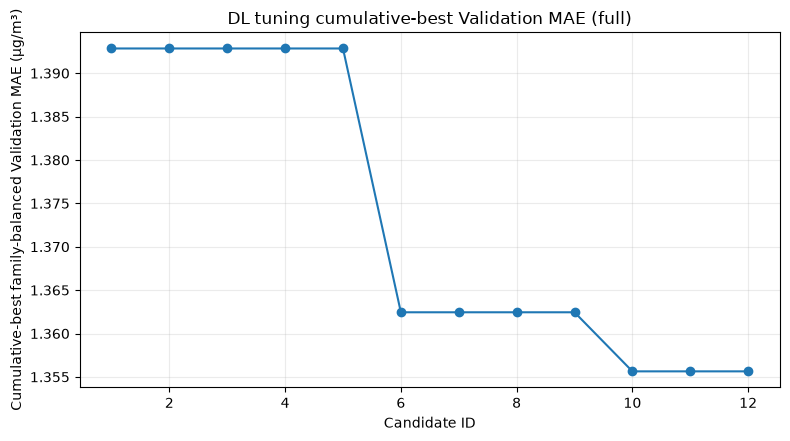

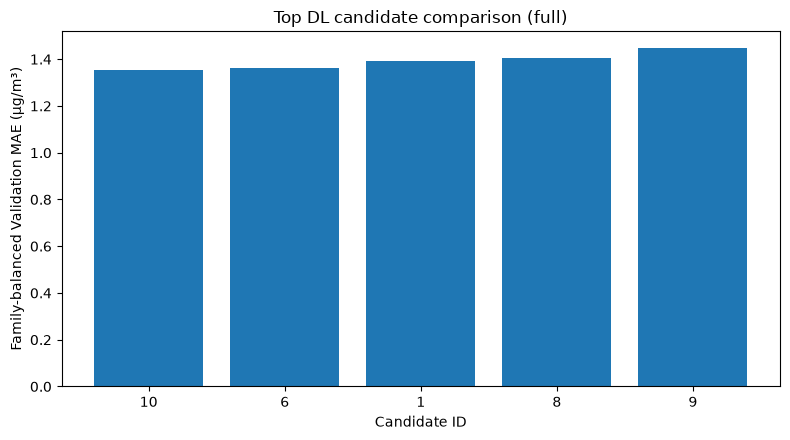

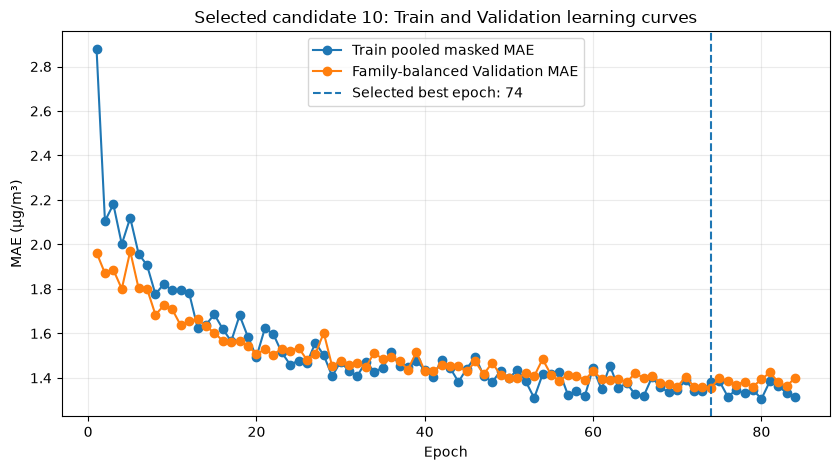

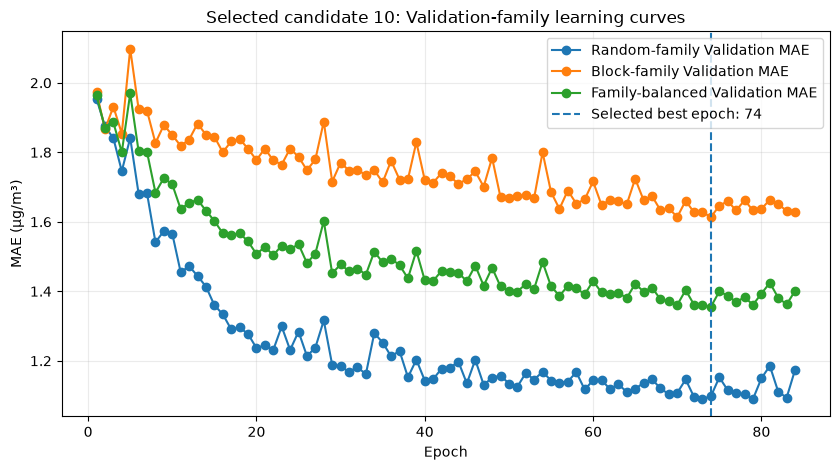

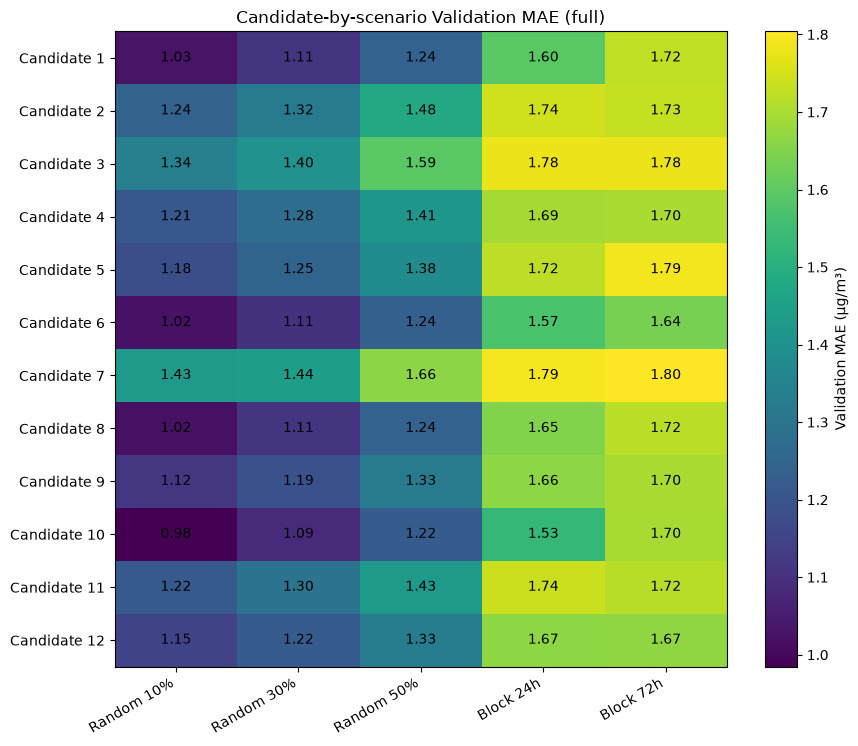

{
  "PipelineVersion": "dl_tuning_v5_results_path_2026-07-24",
  "RunProfile": "full",
  "CandidateCount": 12,
  "SelectedCandidateID": 10,
  "SelectedBestEpoch": 74,
  "TopCandidateSpreadPercent": 6.730360876190559,
  "BoundaryFlags": {
    "context_hours": true,
    "hidden_units": true,
    "recurrent_layers": true,
    "dropout": true,
    "learning_rate": true
  },
  "BoundaryFlagInterpretation": "Descriptive only. Binary search dimensions consist entirely of endpoint values.",
  "ClaimOfExhaustiveSearch": false,
  "CumulativeBestPlot": "C:\\Users\\Msi\\Desktop\\DISSERTATION\\Codes\\results\\deep_learning\\08b_tuning\\dl_tuning_v5_results_path_2026-07-24\\full\\dl_cumulative_best_validation_mae.png",
  "TopCandidatePlot": "C:\\Users\\Msi\\Desktop\\DISSERTATION\\Codes\\results\\deep_learning\\08b_tuning\\dl_tuning_v5_results_path_2026-07-24\\full\\dl_top_candidate_validation_mae.png",
  "TrainValidationLearningCurve": "C:\\Users\\Msi\\Desktop\\DISSERTATION\\Codes\\results\\deep_lea

In [17]:
# ============================================================
# Step 17: Search and learning-curve diagnostics
# ============================================================

ordered_summary_df = (
    summary_df
    .sort_values("CandidateID")
    .reset_index(drop=True)
)

ordered_summary_df["CumulativeBestMAE"] = (
    ordered_summary_df[
        "BestFamilyBalancedValidationMAE"
    ]
    .cummin()
)

# ------------------------------------------------------------
# Figure 1: Candidate-order cumulative-best Validation MAE
# ------------------------------------------------------------

plt.figure(figsize=(8, 4.5))
plt.plot(
    ordered_summary_df["CandidateID"],
    ordered_summary_df["CumulativeBestMAE"],
    marker="o",
)
plt.xlabel("Candidate ID")
plt.ylabel(
    "Cumulative-best family-balanced Validation MAE "
    "(µg/m³)"
)
plt.title(
    f"DL tuning cumulative-best Validation MAE ({RUN_PROFILE})"
)
plt.grid(alpha=0.25)
plt.tight_layout()

cumulative_plot_path = (
    PROFILE_OUTPUT_DIR
    / "dl_cumulative_best_validation_mae.png"
)
plt.savefig(
    cumulative_plot_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------------------
# Figure 2: Top candidate comparison
# ------------------------------------------------------------

top_n = min(5, len(ranked_summary_df))
top_candidates_df = ranked_summary_df.head(top_n).copy()

plt.figure(figsize=(8, 4.5))
plt.bar(
    top_candidates_df[
        "CandidateID"
    ].astype(str),
    top_candidates_df[
        "BestFamilyBalancedValidationMAE"
    ],
)
plt.xlabel("Candidate ID")
plt.ylabel(
    "Family-balanced Validation MAE (µg/m³)"
)
plt.title(
    f"Top DL candidate comparison ({RUN_PROFILE})"
)
plt.tight_layout()

top_plot_path = (
    PROFILE_OUTPUT_DIR
    / "dl_top_candidate_validation_mae.png"
)
plt.savefig(
    top_plot_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------------------
# Read the selected candidate's full epoch history
# ------------------------------------------------------------

best_history_path = Path(
    ranked_summary_df.loc[
        ranked_summary_df["CandidateID"].eq(
            best_candidate_id
        ),
        "HistoryPath",
    ].iloc[0]
)

assert best_history_path.exists()

best_history_df = pd.read_csv(best_history_path)

required_history_columns = {
    "Epoch",
    "TrainPooledMaskedMAEOriginalUnits",
    "RandomMacroValidationMAE",
    "BlockMacroValidationMAE",
    "FamilyBalancedValidationMAE",
}

missing_history_columns = (
    required_history_columns
    - set(best_history_df.columns)
)

assert not missing_history_columns, (
    f"Missing selected-candidate history columns: "
    f"{sorted(missing_history_columns)}"
)

selected_best_epoch = int(
    ranked_summary_df.loc[
        ranked_summary_df["CandidateID"].eq(
            best_candidate_id
        ),
        "BestEpoch",
    ].iloc[0]
)

# ------------------------------------------------------------
# Figure 3: Train-versus-Validation learning curve
# ------------------------------------------------------------

plt.figure(figsize=(8.5, 4.8))
plt.plot(
    best_history_df["Epoch"],
    best_history_df[
        "TrainPooledMaskedMAEOriginalUnits"
    ],
    marker="o",
    label="Train pooled masked MAE",
)
plt.plot(
    best_history_df["Epoch"],
    best_history_df[
        "FamilyBalancedValidationMAE"
    ],
    marker="o",
    label="Family-balanced Validation MAE",
)
plt.axvline(
    selected_best_epoch,
    linestyle="--",
    label=f"Selected best epoch: {selected_best_epoch}",
)
plt.xlabel("Epoch")
plt.ylabel("MAE (µg/m³)")
plt.title(
    f"Selected candidate {best_candidate_id}: "
    "Train and Validation learning curves"
)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

learning_curve_path = (
    PROFILE_OUTPUT_DIR
    / "dl_selected_candidate_train_validation_learning_curve.png"
)
plt.savefig(
    learning_curve_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------------------
# Figure 4: Random-versus-block Validation learning curve
# ------------------------------------------------------------

plt.figure(figsize=(8.5, 4.8))
plt.plot(
    best_history_df["Epoch"],
    best_history_df[
        "RandomMacroValidationMAE"
    ],
    marker="o",
    label="Random-family Validation MAE",
)
plt.plot(
    best_history_df["Epoch"],
    best_history_df[
        "BlockMacroValidationMAE"
    ],
    marker="o",
    label="Block-family Validation MAE",
)
plt.plot(
    best_history_df["Epoch"],
    best_history_df[
        "FamilyBalancedValidationMAE"
    ],
    marker="o",
    label="Family-balanced Validation MAE",
)
plt.axvline(
    selected_best_epoch,
    linestyle="--",
    label=f"Selected best epoch: {selected_best_epoch}",
)
plt.xlabel("Epoch")
plt.ylabel("MAE (µg/m³)")
plt.title(
    f"Selected candidate {best_candidate_id}: "
    "Validation-family learning curves"
)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

family_learning_curve_path = (
    PROFILE_OUTPUT_DIR
    / "dl_selected_candidate_validation_family_learning_curve.png"
)
plt.savefig(
    family_learning_curve_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------------------
# Figure 5: Candidate-by-scenario Validation MAE heatmap
# ------------------------------------------------------------

scenario_display_names = {
    "random10_point": "Random 10%",
    "random30_point": "Random 30%",
    "random50_point": "Random 50%",
    "block24_10percent": "Block 24h",
    "block72_10percent": "Block 72h",
}

scenario_mae_columns = [
    f"Best_{scenario}_MAE"
    for scenario in SCENARIOS
]

missing_scenario_columns = (
    set(scenario_mae_columns)
    - set(ordered_summary_df.columns)
)

assert not missing_scenario_columns, (
    f"Missing scenario MAE columns: "
    f"{sorted(missing_scenario_columns)}"
)

scenario_heatmap_values = (
    ordered_summary_df[
        scenario_mae_columns
    ]
    .to_numpy(dtype=float)
)

plt.figure(
    figsize=(
        9,
        max(3.5, 0.48 * len(ordered_summary_df) + 1.8),
    )
)
heatmap_image = plt.imshow(
    scenario_heatmap_values,
    aspect="auto",
)
plt.colorbar(
    heatmap_image,
    label="Validation MAE (µg/m³)",
)
plt.xticks(
    np.arange(len(SCENARIOS)),
    [
        scenario_display_names[scenario]
        for scenario in SCENARIOS
    ],
    rotation=30,
    ha="right",
)
plt.yticks(
    np.arange(len(ordered_summary_df)),
    [
        f"Candidate {candidate_id}"
        for candidate_id in ordered_summary_df[
            "CandidateID"
        ]
    ],
)

for row_index in range(
    scenario_heatmap_values.shape[0]
):
    for column_index in range(
        scenario_heatmap_values.shape[1]
    ):
        plt.text(
            column_index,
            row_index,
            f"{scenario_heatmap_values[row_index, column_index]:.2f}",
            ha="center",
            va="center",
        )

plt.title(
    f"Candidate-by-scenario Validation MAE ({RUN_PROFILE})"
)
plt.tight_layout()

scenario_heatmap_path = (
    PROFILE_OUTPUT_DIR
    / "dl_candidate_scenario_validation_mae_heatmap.png"
)
plt.savefig(
    scenario_heatmap_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------------------
# Search-boundary and stability diagnostics
# ------------------------------------------------------------

selected_row = candidate_df.loc[
    candidate_df["CandidateID"].eq(
        best_candidate_id
    )
].iloc[0]

boundary_flags = {
    "context_hours": bool(
        selected_row["context_hours"]
        in {
            candidate_df["context_hours"].min(),
            candidate_df["context_hours"].max(),
        }
    ),
    "hidden_units": bool(
        selected_row["hidden_units"]
        in {
            candidate_df["hidden_units"].min(),
            candidate_df["hidden_units"].max(),
        }
    ),
    "recurrent_layers": bool(
        selected_row["recurrent_layers"]
        in {
            candidate_df["recurrent_layers"].min(),
            candidate_df["recurrent_layers"].max(),
        }
    ),
    "dropout": bool(
        selected_row["dropout"]
        in {
            candidate_df["dropout"].min(),
            candidate_df["dropout"].max(),
        }
    ),
    "learning_rate": bool(
        selected_row["learning_rate"]
        in {
            candidate_df["learning_rate"].min(),
            candidate_df["learning_rate"].max(),
        }
    ),
}

diagnostics = {
    "PipelineVersion": PIPELINE_VERSION,
    "RunProfile": RUN_PROFILE,
    "CandidateCount": int(len(summary_df)),
    "SelectedCandidateID": best_candidate_id,
    "SelectedBestEpoch": selected_best_epoch,
    "TopCandidateSpreadPercent": (
        float(
            (
                top_candidates_df[
                    "BestFamilyBalancedValidationMAE"
                ].max()
                - top_candidates_df[
                    "BestFamilyBalancedValidationMAE"
                ].min()
            )
            / top_candidates_df[
                "BestFamilyBalancedValidationMAE"
            ].min()
            * 100.0
        )
        if len(top_candidates_df) > 1
        else 0.0
    ),
    "BoundaryFlags": boundary_flags,
    "BoundaryFlagInterpretation": (
        "Descriptive only. Binary search dimensions consist entirely "
        "of endpoint values."
    ),
    "ClaimOfExhaustiveSearch": False,
    "CumulativeBestPlot": str(cumulative_plot_path),
    "TopCandidatePlot": str(top_plot_path),
    "TrainValidationLearningCurve": str(
        learning_curve_path
    ),
    "ValidationFamilyLearningCurve": str(
        family_learning_curve_path
    ),
    "CandidateScenarioHeatmap": str(
        scenario_heatmap_path
    ),
}

if RUN_PROFILE == "full":
    best_through_8 = float(
        ordered_summary_df.loc[
            ordered_summary_df["CandidateID"] <= 8,
            "BestFamilyBalancedValidationMAE",
        ].min()
    )

    best_through_10 = float(
        ordered_summary_df.loc[
            ordered_summary_df["CandidateID"] <= 10,
            "BestFamilyBalancedValidationMAE",
        ].min()
    )

    final_best = float(
        ordered_summary_df[
            "BestFamilyBalancedValidationMAE"
        ].min()
    )

    diagnostics.update({
        "BestMAEThroughCandidate8": best_through_8,
        "BestMAEThroughCandidate10": best_through_10,
        "FinalBestMAE": final_best,
        "ImprovementAfterCandidate8": (
            best_through_8 - final_best
        ),
        "ImprovementAfterCandidate10": (
            best_through_10 - final_best
        ),
    })

diagnostics_path = (
    PROFILE_OUTPUT_DIR
    / "dl_tuning_diagnostics.json"
)

diagnostics_path.write_text(
    json.dumps(diagnostics, indent=2),
    encoding="utf-8",
)

print(json.dumps(diagnostics, indent=2))

In [18]:
# ============================================================
# Step 18: Save tuning manifest and final audit
# ============================================================

required_output_paths = [
    PROFILE_OUTPUT_DIR / "dl_candidate_table.csv",
    PROFILE_OUTPUT_DIR / "validation_target_audit.csv",
    PROFILE_OUTPUT_DIR / "dl_candidate_tuning_summary.csv",
    PROFILE_OUTPUT_DIR / "dl_all_candidate_epoch_history.csv",
    PROFILE_OUTPUT_DIR / "dl_ranked_candidate_summary.csv",
    PROFILE_OUTPUT_DIR / "dl_best_graph_tuning_configuration.json",
    PROFILE_OUTPUT_DIR / "dl_tuning_diagnostics.json",
    PROFILE_OUTPUT_DIR / "dl_cumulative_best_validation_mae.png",
    PROFILE_OUTPUT_DIR / "dl_top_candidate_validation_mae.png",
    PROFILE_OUTPUT_DIR
    / "dl_selected_candidate_train_validation_learning_curve.png",
    PROFILE_OUTPUT_DIR
    / "dl_selected_candidate_validation_family_learning_curve.png",
    PROFILE_OUTPUT_DIR
    / "dl_candidate_scenario_validation_mae_heatmap.png",
]

for required_output_path in required_output_paths:
    assert required_output_path.exists(), (
        f"Missing output: {required_output_path}"
    )

for candidate_id in PROFILE["candidate_ids"]:
    assert (
        PROFILE_MODEL_DIR
        / f"candidate_{candidate_id:02d}_best.pt"
    ).exists()

manifest = {
    "PipelineVersion": PIPELINE_VERSION,
    "Status": (
        "pilot_complete"
        if RUN_PROFILE == "pilot"
        else "full_validation_tuning_complete"
    ),
    "Notebook": (
        "08b_deep_learning_graph_recurrent_pilot_and_tuning"
    ),
    "RunProfile": RUN_PROFILE,
    "TestDataUsedForSelection": False,
    "ModelFamily": (
        "compact_GRIN_inspired_graph_enhanced_BiGRU"
    ),
    "PrimaryGraph": "fixed_directed_top3_IDW",
    "CandidateIDs": PROFILE["candidate_ids"],
    "CandidateCount": len(PROFILE["candidate_ids"]),
    "TrainSamplesPerEpoch": PROFILE[
        "train_samples_per_epoch"
    ],
    "ValidationScope": (
        "fixed_subset"
        if PROFILE[
            "maximum_validation_windows_per_scenario"
        ]
        is not None
        else "all_fixed_validation_targets"
    ),
    "MaximumEpochs": PROFILE["maximum_epochs"],
    "Patience": PROFILE["patience"],
    "BatchSize": BATCH_SIZE,
    "ValidationBatchSize": VALIDATION_BATCH_SIZE,
    "GradientClipNorm": GRADIENT_CLIP_NORM,
    "Loss": (
        "window_balanced_masked_L1_standardised_PM25_at_"
        "all_artificially_hidden_centre_step_nodes"
    ),
    "EarlyStoppingMetric": (
        "FamilyBalancedValidationMAE_original_units"
    ),
    "NaNSafeTargetHandling": {
        "NonTargetNaturalMissingTruth": (
            "replaced_with_zero_after_target_finiteness_assertion"
        ),
        "MaskedReduction": (
            "torch_where_before_window_reduction"
        ),
    },
    "TrainingHistoryMetrics": {
        "OptimisationLoss": (
            "window-balanced masked L1 in standardised units"
        ),
        "PooledTrainDiagnostic": (
            "target-pooled masked MAE in original PM2.5 units"
        ),
    },
    "DiagnosticFigures": {
        "CumulativeBest": str(cumulative_plot_path),
        "TopCandidates": str(top_plot_path),
        "TrainValidationLearningCurve": str(
            learning_curve_path
        ),
        "ValidationFamilyLearningCurve": str(
            family_learning_curve_path
        ),
        "CandidateScenarioHeatmap": str(
            scenario_heatmap_path
        ),
    },
    "TrainMasking": (
        "deterministic_epoch_wise_resampling"
    ),
    "BlockBackgroundMasking": {
        "Purpose": (
            "represent concurrent station gaps in the fixed block scenarios"
        ),
        "ExpectedLocalCoverageOnNonTargetNodes": (
            BLOCK_BACKGROUND_COVERAGE
        ),
        "MaximumBlocksPerNonTargetNodePerSample": 1,
    },
    "ModelInitialisationSeed": MODEL_INITIALISATION_SEED,
    "TrainMaskBaseSeed": TRAIN_MASK_BASE_SEED,
    "TrainOrderBaseSeed": TRAIN_ORDER_BASE_SEED,
    "SelectedCandidateID": best_candidate_id,
    "SelectedConfigurationPath": str(
        best_configuration_path
    ),
    "OverallTuningSecondsThisSession": float(
        overall_tuning_seconds
    ),
    "TotalCandidateWallSecondsAcrossCandidates": float(
        summary_df["TotalCandidateWallSeconds"].sum()
    ),
    "Device": str(DEVICE),
    "GPU": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "PyTorchVersion": torch.__version__,
    "CUDAReportedByPyTorch": torch.version.cuda,
    "DeterministicAlgorithmsWarnOnly": True,
    "CuDNNBenchmark": torch.backends.cudnn.benchmark,
    "CuDNNDeterministic": (
        torch.backends.cudnn.deterministic
    ),
    "ContractFingerprint": contract_fingerprint,
    "OutputDirectory": str(PROFILE_OUTPUT_DIR),
    "ModelDirectory": str(PROFILE_MODEL_DIR),
}

manifest_path = (
    PROFILE_OUTPUT_DIR / "dl_tuning_manifest.json"
)

manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print("Deep-learning tuning audit passed.")
print("Manifest:", manifest_path)

if RUN_PROFILE == "pilot":
    print(
        "\nPILOT COMPLETE.\n"
        "Change only RUN_PROFILE to 'full', restart the kernel, "
        "and run all cells to begin the locked 12-candidate tuning."
    )
else:
    print(
        "\nFULL VALIDATION TUNING COMPLETE.\n"
        "Do not retune after this point. Next notebook: "
        "08c frozen final fit, zero-neighbour ablation and Test evaluation."
    )

Deep-learning tuning audit passed.
Manifest: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08b_tuning\dl_tuning_v5_results_path_2026-07-24\full\dl_tuning_manifest.json

FULL VALIDATION TUNING COMPLETE.
Do not retune after this point. Next notebook: 08c frozen final fit, zero-neighbour ablation and Test evaluation.


## Interpretation rule

A full-profile result identifies the best configuration **within the predefined compact search budget**. It does not establish a global optimum.

The tuning diagnostics will support one of two defensible conclusions:

- if the cumulative-best curve stabilises and late candidates provide negligible improvement, the compact search appeared stable within its predefined budget;
- if meaningful late improvement remains, the restricted search budget must be acknowledged as a limitation.

Neither the pilot nor the full tuning notebook may be used to alter Test masks or inspect Test performance.